# **IMPORTING LIBRARIES AND THE DATASET**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
df=pd.read_csv('/content/messy_telecom_churn_100k.csv')

# **UNDERSTANDING THE DATASET**

In [2]:
df.shape

(100000, 18)

In [3]:
df.head()

,customer_id,gender,age,signup_date,contract_type,tenure_months,internet_service,tech_support,online_security,paperless_billing,payment_method,monthly_charges,total_charges,avg_monthly_gb,avg_call_minutes,num_support_tickets,late_payments,churn
0,C179528,FEMALE,48.0,22/04/2024,One year,30.0,No,No internet service,No internet service,Yes,Bank transfer,29.51,897.19,0.0,NaN,1.0,1.0,No
1,C153876,Female,47.0,2024-03-07,Two year,31.0,DSL,No,No,Yes,Mailed check,55.99,1700.92,193.4,543.2,1.0,2.0,No
2,C109777,Male,NaN,2021-07-31,One year,63.0,No,No internet service,No internet service,Yes,Bank transfer,18.00,1161.13,0.0,399.5,1.0,1.0,No
3,C106167,Male,24.0,2025-09-21,Month-to-month,13.0,Fiber optic,Yes,No,No,Bank transfer,72.14,944.7,185.3,535.2,4.0,0.0,No
4,C122020,Male,54.0,2025-10-06,Month-to-month,12.0,NaN,No,Yes,No,Bank transfer,78.69,940.68,147.6,319.4,1.0,0.0,Yes


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   customer_id          100000 non-null  object 
 1   gender               100000 non-null  object 
 2   age                  96087 non-null   float64
 3   signup_date          96994 non-null   object 
 4   contract_type        100000 non-null  object 
 5   tenure_months        98104 non-null   float64
 6   internet_service     97069 non-null   object 
 7   tech_support         100000 non-null  object 
 8   online_security      100000 non-null  object 
 9   paperless_billing    100000 non-null  object 
 10  payment_method       97946 non-null   object 
 11  monthly_charges      94649 non-null   float64
 12  total_charges        100000 non-null  object 
 13  avg_monthly_gb       92972 non-null   float64
 14  avg_call_minutes     94991 non-null   float64
 15  num_support_ticket

# **CHANGING THE DATA TYPE OF THE FEATURES**

In [5]:
df["total_charges"] = pd.to_numeric(
    df["total_charges"].astype(str).str.strip(),
    errors="coerce")
s = df["signup_date"]
iso = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
dmy = pd.to_datetime(s, format="%d/%m/%Y", errors="coerce")
df["signup_date"] = iso.fillna(dmy)
print(df.dtypes)

customer_id                    object
gender                         object
age                           float64
signup_date            datetime64[ns]
contract_type                  object
tenure_months                 float64
internet_service               object
tech_support                   object
online_security                object
paperless_billing              object
payment_method                 object
monthly_charges               float64
total_charges                 float64
avg_monthly_gb                float64
avg_call_minutes              float64
num_support_tickets           float64
late_payments                 float64
churn                          object
dtype: object


# **REMOVING DUPLICATES**

In [6]:
print("Duplicates before:", df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicates after:", df.duplicated().sum())
print("New shape:", df.shape)

Duplicates before: 1805
Duplicates after: 0
New shape: (98195, 18)


# **CHECKING FOR NULL DATA**

In [7]:
df.isnull().sum()

,0
customer_id,0
gender,0
age,3858
signup_date,2946
contract_type,0
tenure_months,1874
internet_service,2877
tech_support,0
online_security,0
paperless_billing,0


# **HANDLING MISSING DATA**

In [8]:
# Keep the churn column as the prediction target.
# Rows with an unknown target cannot be used for supervised training,
# so exclude only those rows (the churn column itself is NOT removed).
print("Missing churn labels:", df["churn"].isna().sum())

df = df.loc[df["churn"].notna()].copy()
df["churn"] = df["churn"].astype(str).str.strip()

# Keep only the two expected target labels.
unexpected_labels = set(df["churn"].unique()) - {"Yes", "No"}
if unexpected_labels:
    raise ValueError(f"Unexpected churn labels found: {unexpected_labels}")

print("Churn column retained:", "churn" in df.columns)
print("Rows available for supervised learning:", len(df))
print("\nChurn distribution:")
print(df["churn"].value_counts())

Missing churn labels: 300
Churn column retained: True
Rows available for supervised learning: 97895

Churn distribution:
churn
No     75753
Yes    22142
Name: count, dtype: int64


# **STANDARDIZING CATEGORIES**

In [9]:

import numpy as np

# Categorical predictor columns
categorical_cols = [
    "gender",
    "contract_type",
    "internet_service",
    "tech_support",
    "online_security",
    "paperless_billing",
    "payment_method"]

# Standardize gender
df["gender"] = df["gender"].str.lower()

gender_mapping = {
    "male": "Male",
    "m": "Male",
    "female": "Female",
    "f": "Female",
    "other": "Other",
    "unknown": np.nan
}

df["gender"] = df["gender"].map(gender_mapping)

# Standardize contract type
df["contract_type"] = (
    df["contract_type"]
    .str.lower()
    .str.replace("-", " ", regex=False)
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

contract_mapping = {
    "month to month": "Month-to-month",
    "one year": "One year",
    "two year": "Two year"
}

df["contract_type"] = df["contract_type"].map(
    contract_mapping
)

# Replace Unknown with missing values in predictors
df[categorical_cols] = df[categorical_cols].replace(
    r"(?i)^unknown$", np.nan, regex=True
)

print("Gender categories:")
print(df["gender"].value_counts(dropna=False))

print("\nContract categories:")
print(df["contract_type"].value_counts(dropna=False))

print("\nRemaining categorical missing values:")
print(df[categorical_cols].isnull().sum())


Gender categories:
gender
Male      47986
Female    47938
Other      1016
NaN         955
Name: count, dtype: int64

Contract categories:
contract_type
Month-to-month    54071
One year          24395
Two year          19429
Name: count, dtype: int64

Remaining categorical missing values:
gender                955
contract_type           0
internet_service     2871
tech_support            0
online_security         0
paperless_billing       0
payment_method       2011
dtype: int64


# **SETTING UP RANGE FOR THE FEATURES**

In [10]:
df.loc[
    (df["age"] < 18) | (df["age"] > 100),
    "age"
] = np.nan
df.loc[df["tenure_months"] > 72, "tenure_months"] = np.nan
df.loc[(df["monthly_charges"] <= 0) | (df["monthly_charges"] > 200), "monthly_charges"] = np.nan
df.loc[df["num_support_tickets"] > 10, "num_support_tickets"] = np.nan
df.loc[
    df["total_charges"] < 0,
    "total_charges"
] = np.nan
df.loc[
    df["avg_monthly_gb"] > 2000,
    "avg_monthly_gb"
] = np.nan
df.loc[
    df["avg_call_minutes"] > 1500,
    "avg_call_minutes"
] = np.nan
print("Invalid values handled.")

Invalid values handled.


In [11]:
df["signup_date"] = pd.to_datetime(df["signup_date"], errors="coerce")
if df["signup_date"].isnull().any() and not df["signup_date"].mode().empty:
    df["signup_date"] = df["signup_date"].fillna(df["signup_date"].mode()[0])

In [12]:
# Do NOT impute predictor columns using the entire dataset.
# Imputation is performed inside the preprocessing Pipeline, so each
# cross-validation fold learns medians/modes only from its training fold.
print("Missing values before train-test split:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())
print("\nPredictor missing values will be handled by the preprocessing pipeline.")

Missing values before train-test split:
customer_id               0
gender                  955
age                    4157
signup_date               0
contract_type             0
tenure_months          1961
internet_service       2871
tech_support              0
online_security           0
paperless_billing         0
payment_method         2011
monthly_charges        5390
total_charges            78
avg_monthly_gb         7083
avg_call_minutes       4901
num_support_tickets    5408
late_payments          2946
churn                     0
dtype: int64

Total missing values: 37761

Predictor missing values will be handled by the preprocessing pipeline.


In [13]:
# Keep age numeric while preserving missing values for the pipeline imputer.
df["age"] = df["age"].round()

In [14]:

numerical_cols = df.select_dtypes(
    include=np.number
).columns

for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    print(
        col,
        "Outliers:",
        len(outliers)
    )


age Outliers: 420
tenure_months Outliers: 0
monthly_charges Outliers: 0
total_charges Outliers: 3334
avg_monthly_gb Outliers: 1826
avg_call_minutes Outliers: 660
num_support_tickets Outliers: 6469
late_payments Outliers: 5928


In [15]:

print("Final Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())
print("\nDuplicate Rows:")
print(df.duplicated().sum())
print("\nData Types:")
print(df.dtypes)
print("\nFirst 5 Rows:")
display(df.head())

Final Dataset Shape: (97895, 18)

Missing Values:
customer_id               0
gender                  955
age                    4157
signup_date               0
contract_type             0
tenure_months          1961
internet_service       2871
tech_support              0
online_security           0
paperless_billing         0
payment_method         2011
monthly_charges        5390
total_charges            78
avg_monthly_gb         7083
avg_call_minutes       4901
num_support_tickets    5408
late_payments          2946
churn                     0
dtype: int64

Duplicate Rows:
0

Data Types:
customer_id                    object
gender                         object
age                           float64
signup_date            datetime64[ns]
contract_type                  object
tenure_months                 float64
internet_service               object
tech_support                   object
online_security                object
paperless_billing              object
payment_method       

,customer_id,gender,age,signup_date,contract_type,tenure_months,internet_service,tech_support,online_security,paperless_billing,payment_method,monthly_charges,total_charges,avg_monthly_gb,avg_call_minutes,num_support_tickets,late_payments,churn
0,C179528,Female,48.0,2024-04-22,One year,30.0,No,No internet service,No internet service,Yes,Bank transfer,29.51,897.19,0.0,NaN,1.0,1.0,No
1,C153876,Female,47.0,2024-03-07,Two year,31.0,DSL,No,No,Yes,Mailed check,55.99,1700.92,193.4,543.2,1.0,2.0,No
2,C109777,Male,NaN,2021-07-31,One year,63.0,No,No internet service,No internet service,Yes,Bank transfer,18.00,1161.13,0.0,399.5,1.0,1.0,No
3,C106167,Male,24.0,2025-09-21,Month-to-month,13.0,Fiber optic,Yes,No,No,Bank transfer,72.14,944.70,185.3,535.2,4.0,0.0,No
4,C122020,Male,54.0,2025-10-06,Month-to-month,12.0,NaN,No,Yes,No,Bank transfer,78.69,940.68,147.6,319.4,1.0,0.0,Yes


# **univariate visualization**

**categorical**

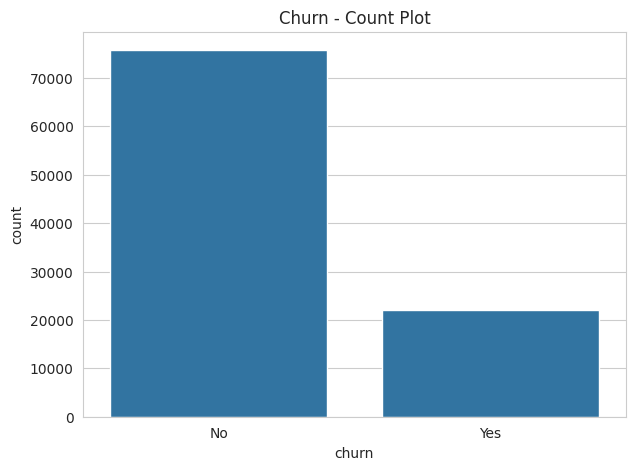

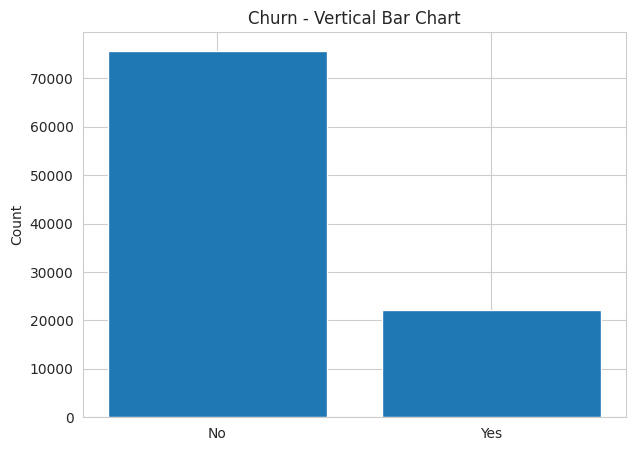

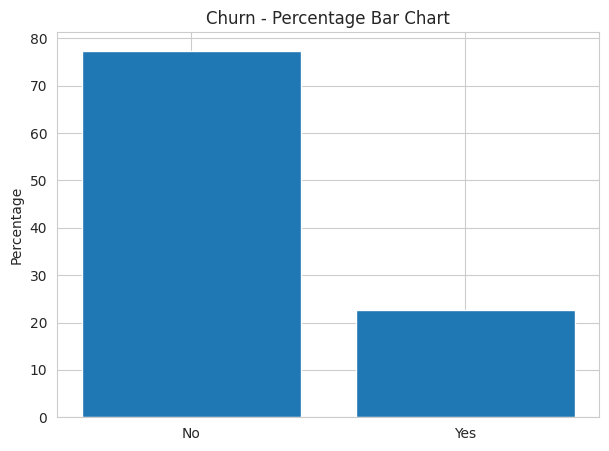

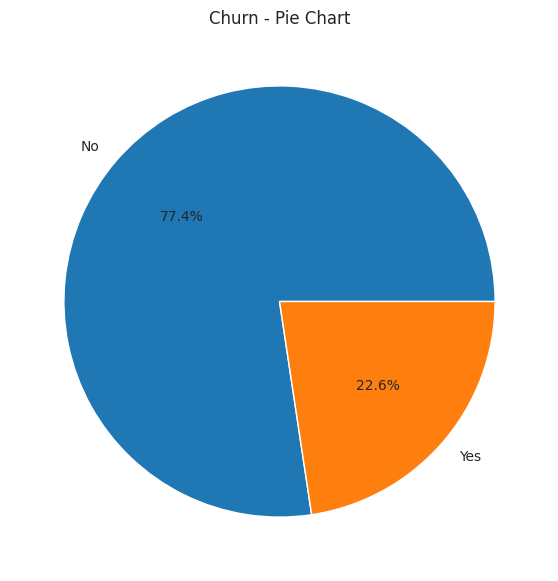

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# Target distribution
churn_counts = df["churn"].dropna().value_counts()
churn_percent = df["churn"].dropna().value_counts(normalize=True) * 100

labels = churn_counts.index.astype(str)
values = churn_counts.values

# 1. Count Plot
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="churn")
plt.title("Churn - Count Plot")
plt.show()

# 2. Vertical Bar Chart
plt.figure(figsize=(7, 5))
plt.bar(labels, values)
plt.title("Churn - Vertical Bar Chart")
plt.ylabel("Count")
plt.show()
# 4. Percentage Bar Chart
plt.figure(figsize=(7, 5))
plt.bar(labels, churn_percent.values)
plt.title("Churn - Percentage Bar Chart")
plt.ylabel("Percentage")
plt.show()

# 5. Pie Chart
plt.figure(figsize=(7, 7))
plt.pie(values, labels=labels, autopct="%1.1f%%")
plt.title("Churn - Pie Chart")
plt.show()

**numerical**

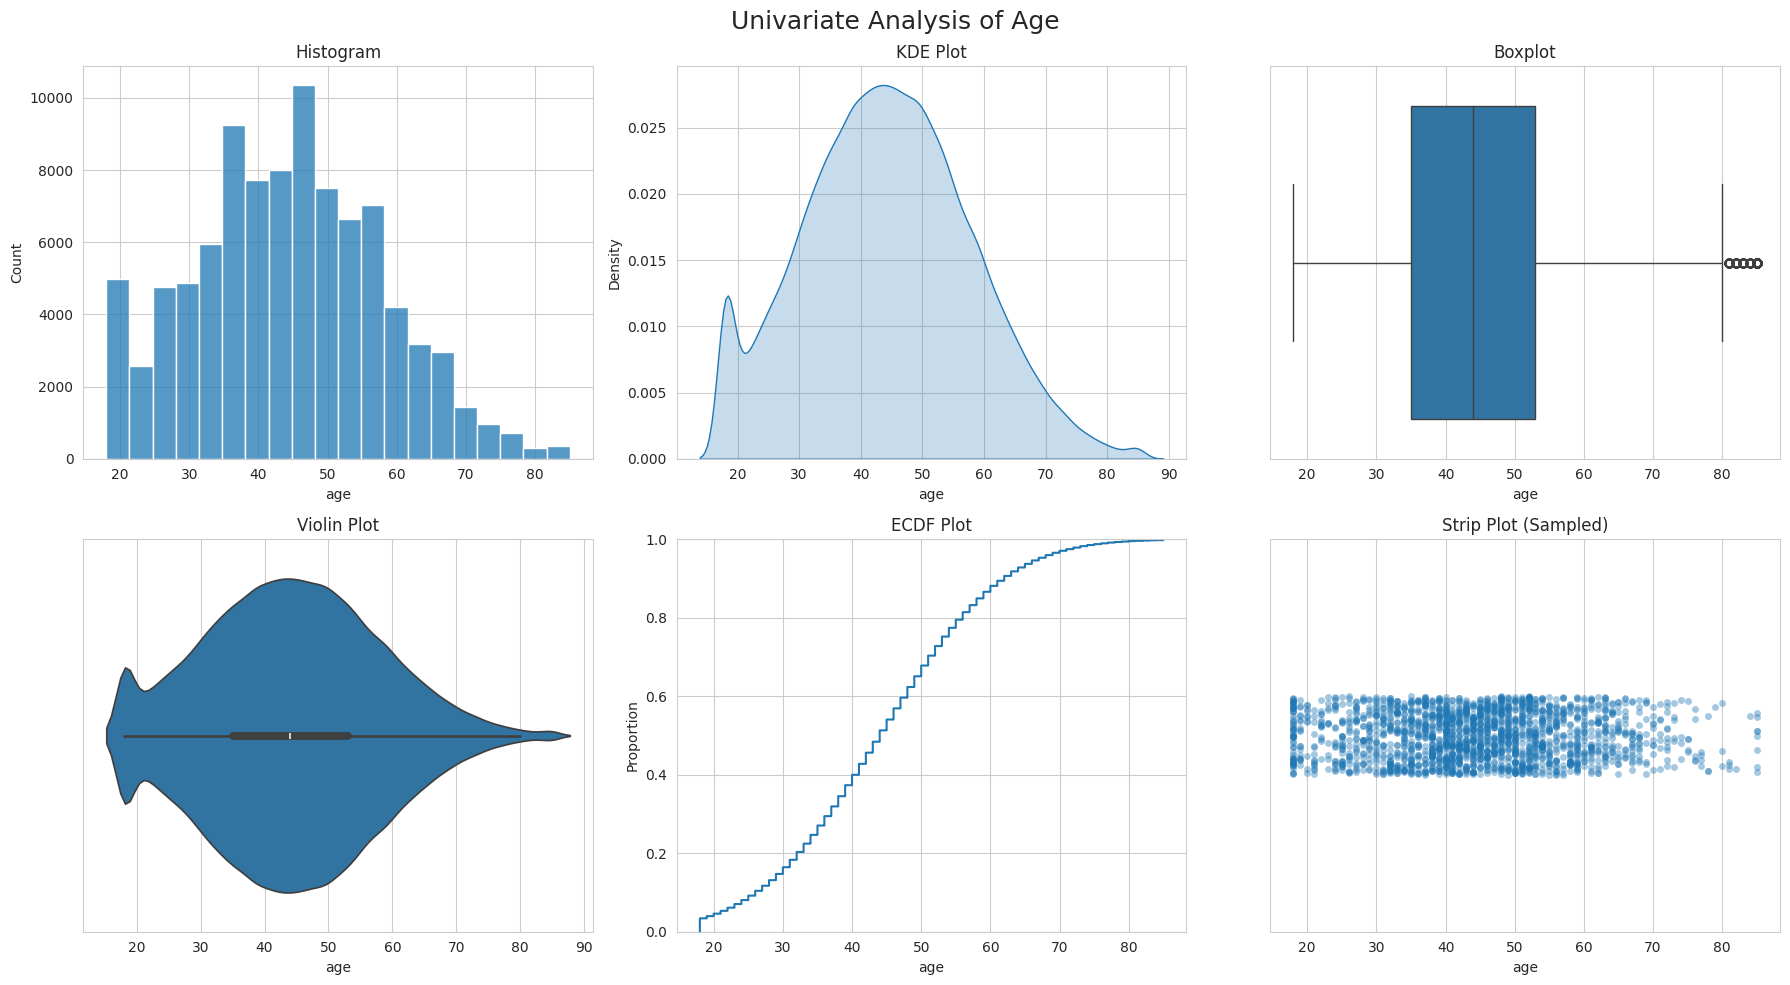

In [17]:

import matplotlib.pyplot as plt
import seaborn as sns

age_data = df["age"].dropna()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Univariate Analysis of Age", fontsize=18)

# 1. Histogram
sns.histplot(age_data, bins=20, kde=False, ax=axes[0, 0])
axes[0, 0].set_title("Histogram")

# 2. KDE Plot
sns.kdeplot(age_data, fill=True, ax=axes[0, 1])
axes[0, 1].set_title("KDE Plot")

# 3. Boxplot
sns.boxplot(x=age_data, ax=axes[0, 2])
axes[0, 2].set_title("Boxplot")

# 4. Violin Plot
sns.violinplot(x=age_data, ax=axes[1, 0])
axes[1, 0].set_title("Violin Plot")

# 5. ECDF Plot
sns.ecdfplot(age_data, ax=axes[1, 1])
axes[1, 1].set_title("ECDF Plot")

# 6. Strip Plot
sns.stripplot(x=age_data.sample(
    n=min(2000, len(age_data)),
    random_state=42
), ax=axes[1, 2], alpha=0.4)
axes[1, 2].set_title("Strip Plot (Sampled)")

plt.tight_layout()
plt.show()


# **bivariate visualization**

**numerical & categorical**

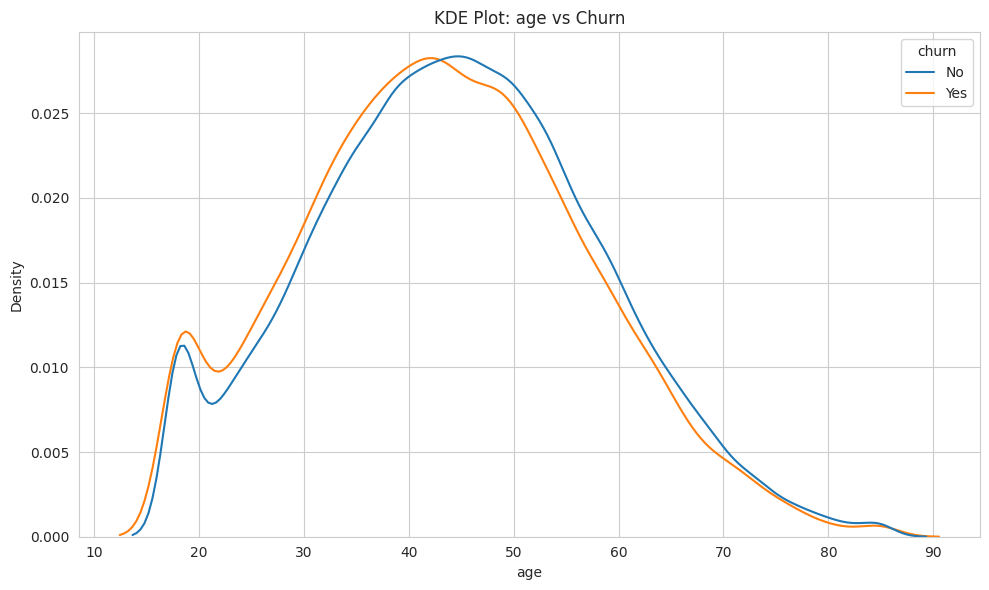

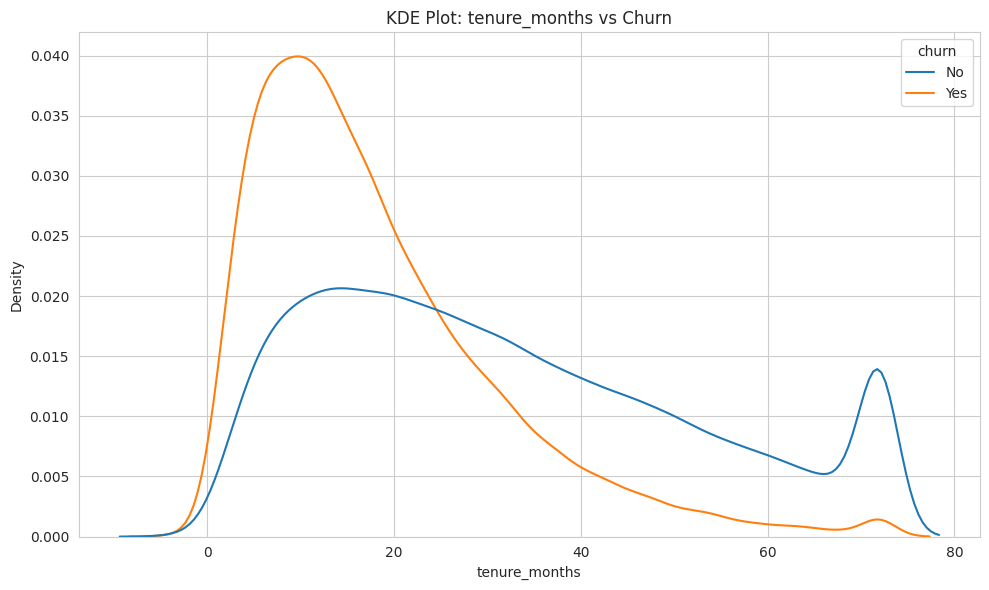

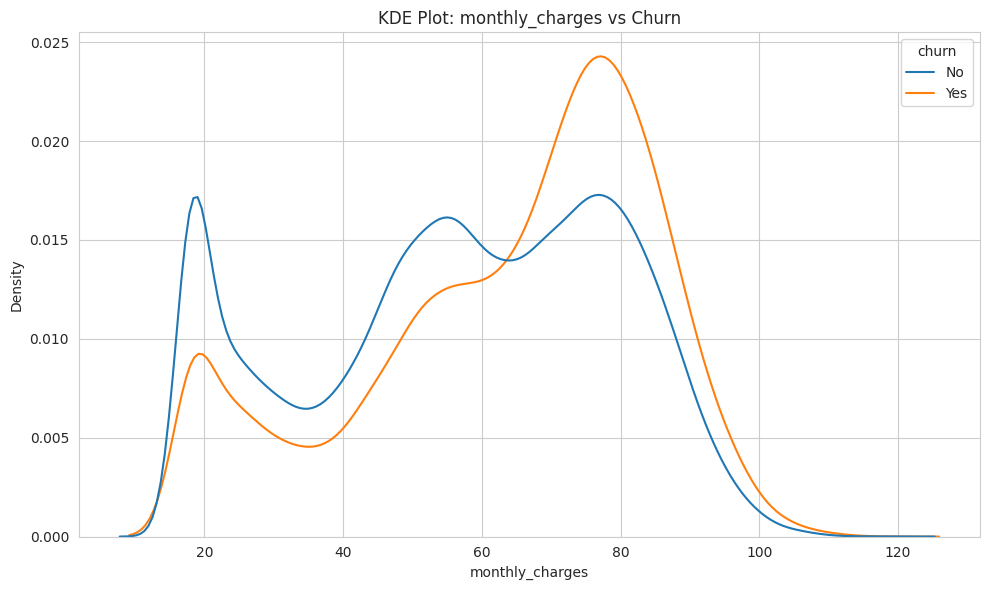

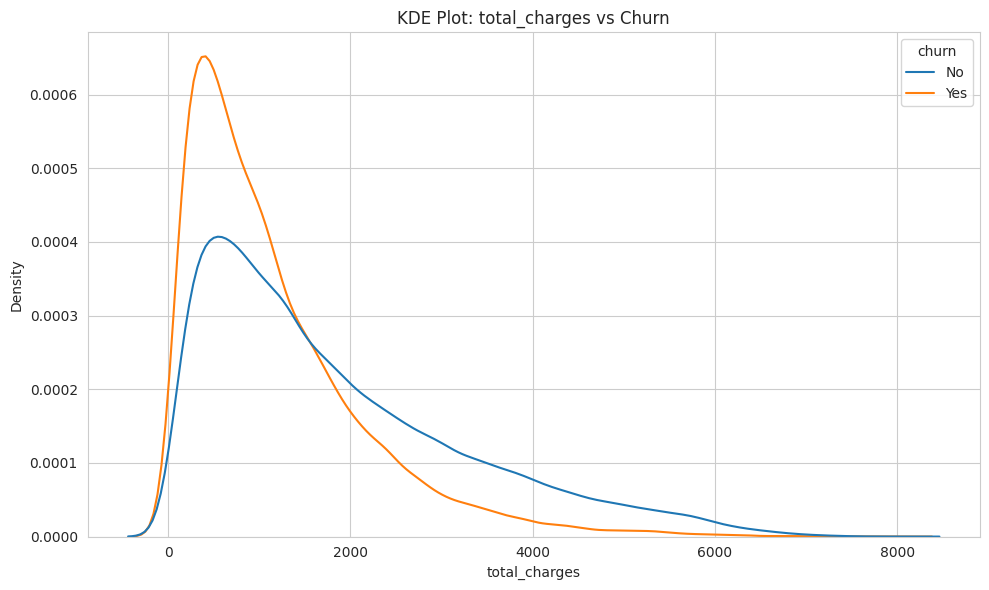

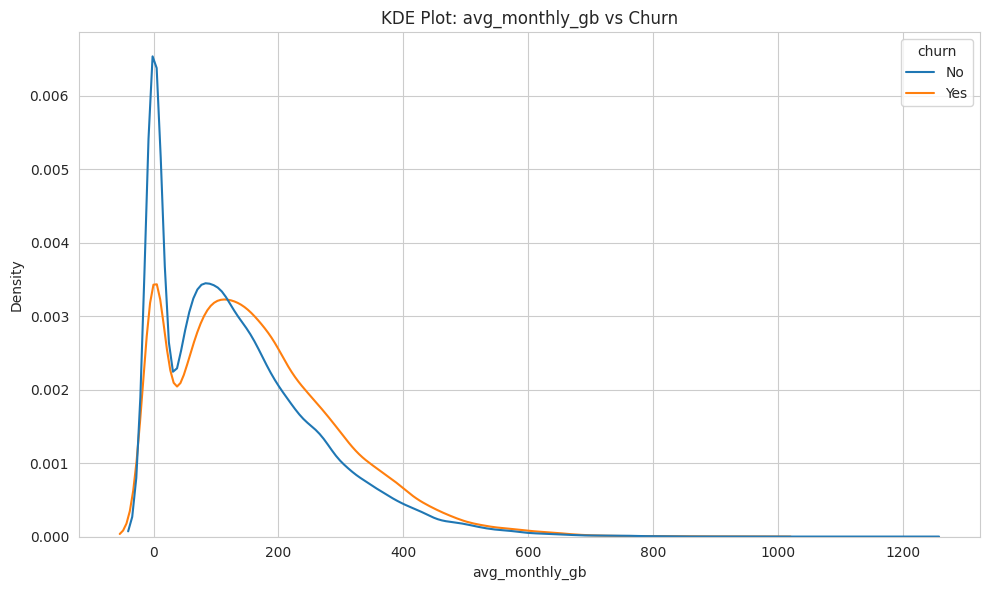

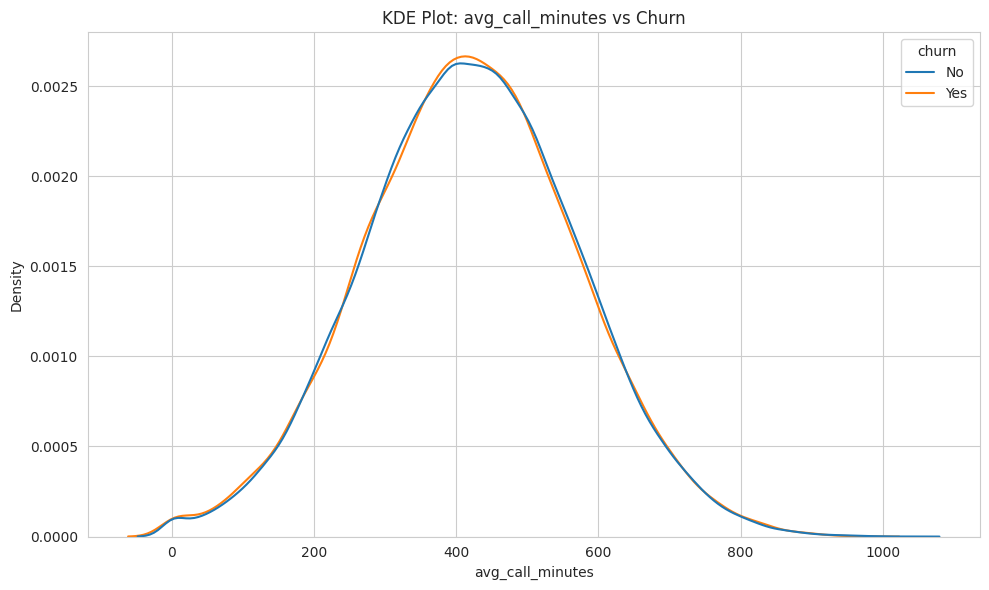

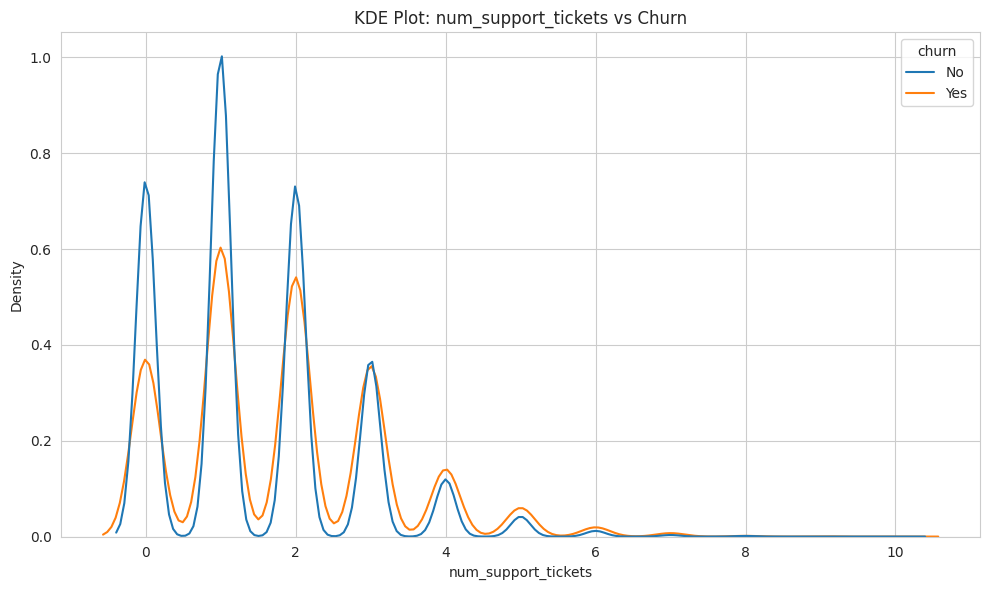

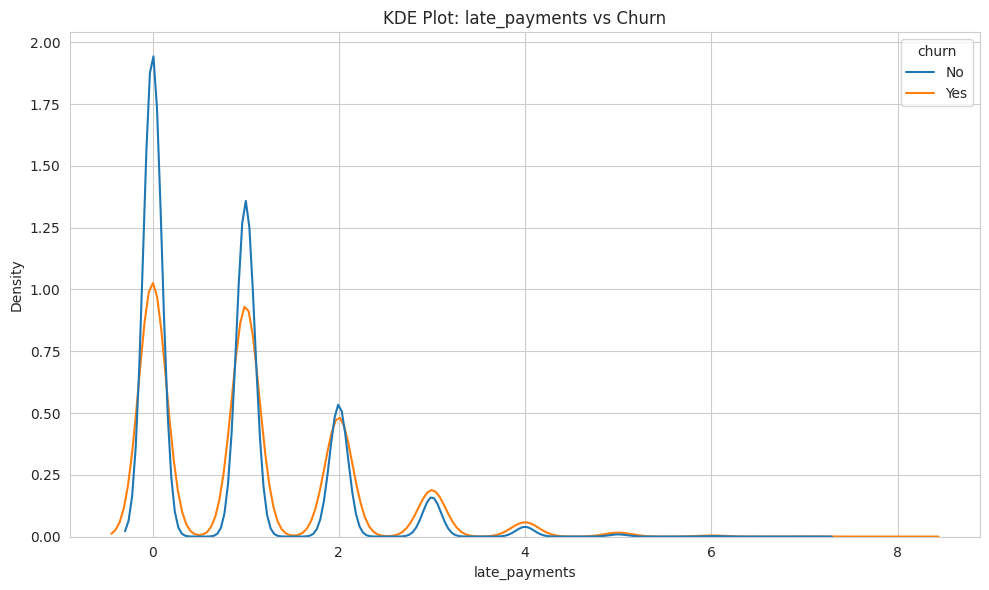

In [18]:

numerical_cols = [
    "age",
    "tenure_months",
    "monthly_charges",
    "total_charges",
    "avg_monthly_gb",
    "avg_call_minutes",
    "num_support_tickets",
    "late_payments"
]

for col in numerical_cols:

    plot_data = df[["churn", col]].dropna()

    plt.figure(figsize=(10, 6))

    sns.kdeplot(
        data=plot_data,
        x=col,
        hue="churn",
        common_norm=False
    )

    plt.title(f"KDE Plot: {col} vs Churn")
    plt.xlabel(col)
    plt.ylabel("Density")
    plt.tight_layout()
    plt.show()


**categorical & categorical**

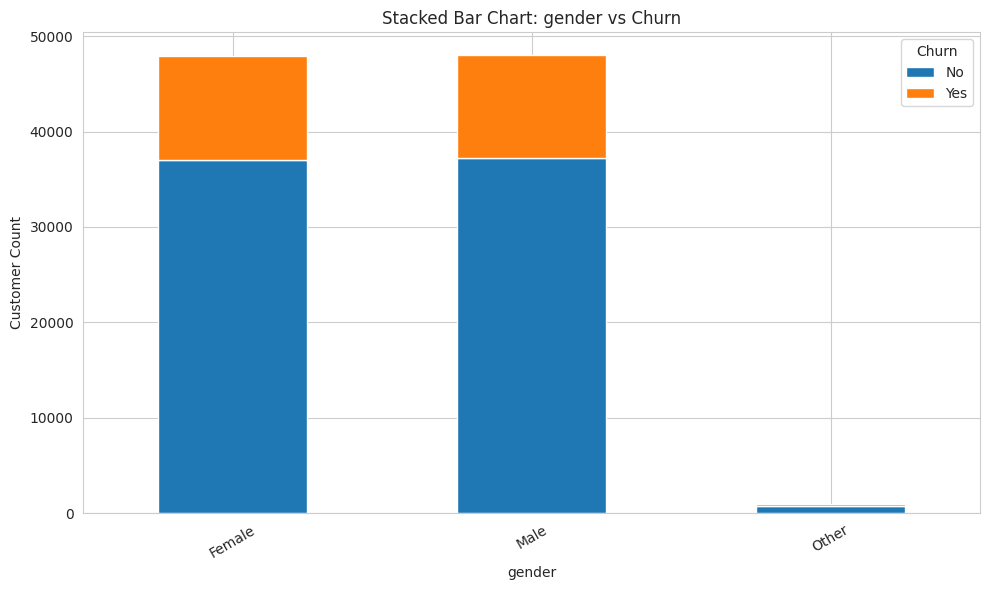

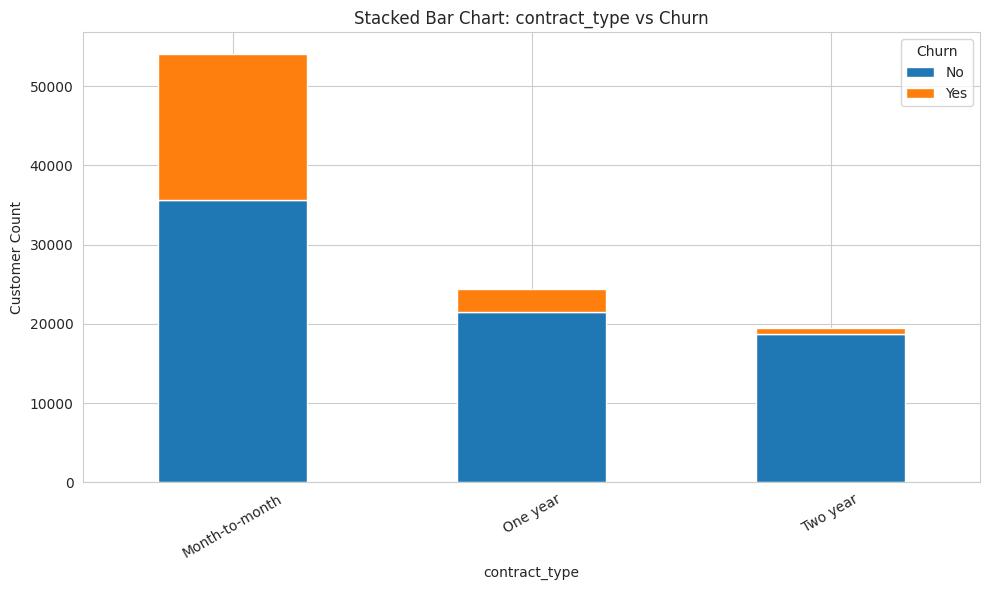

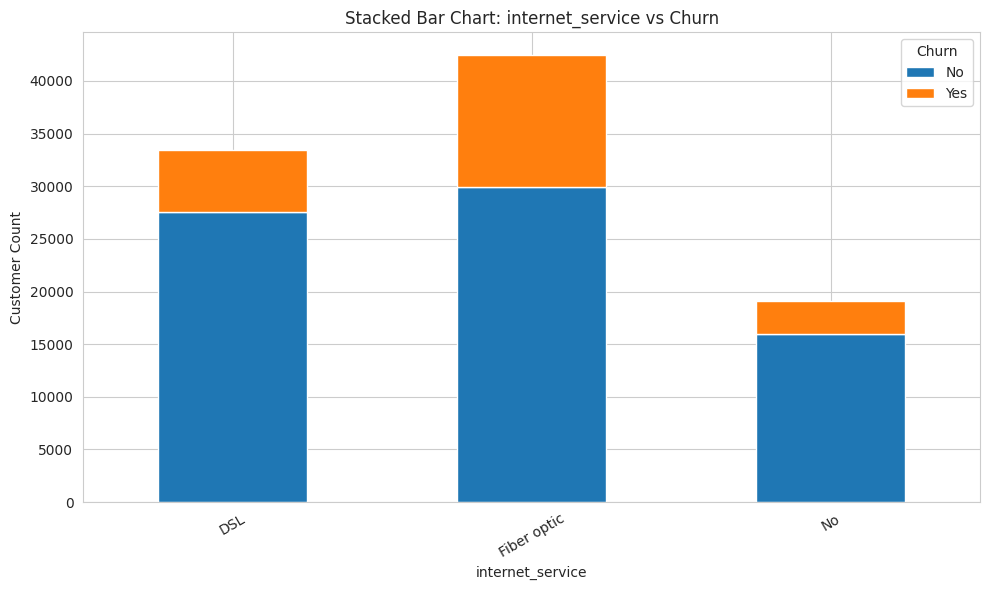

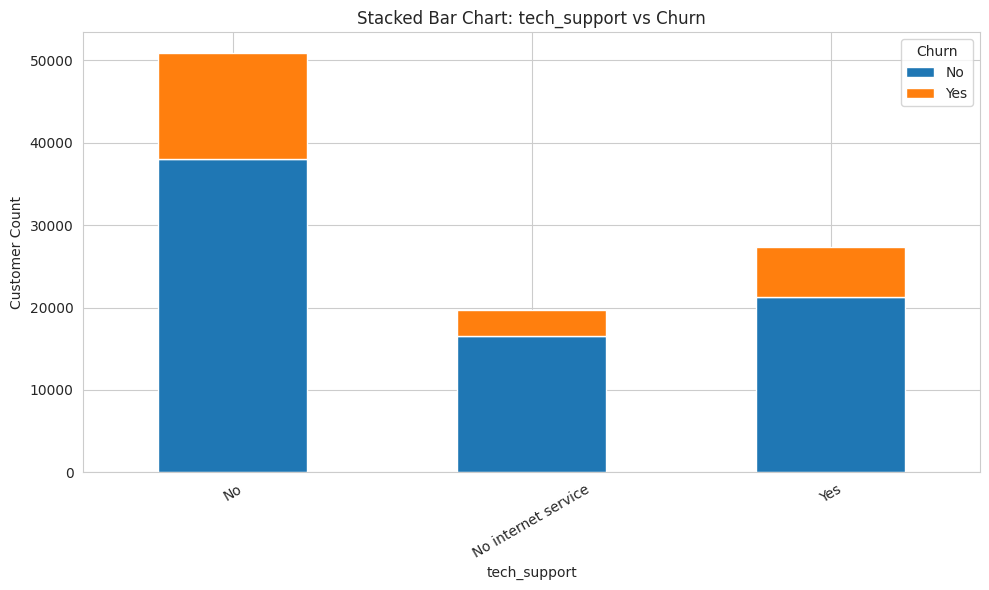

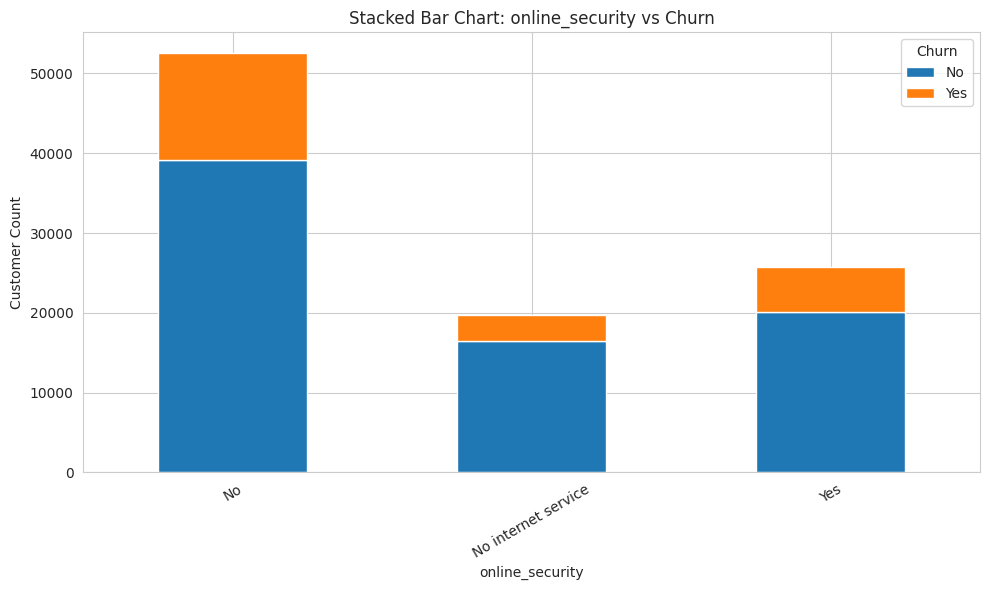

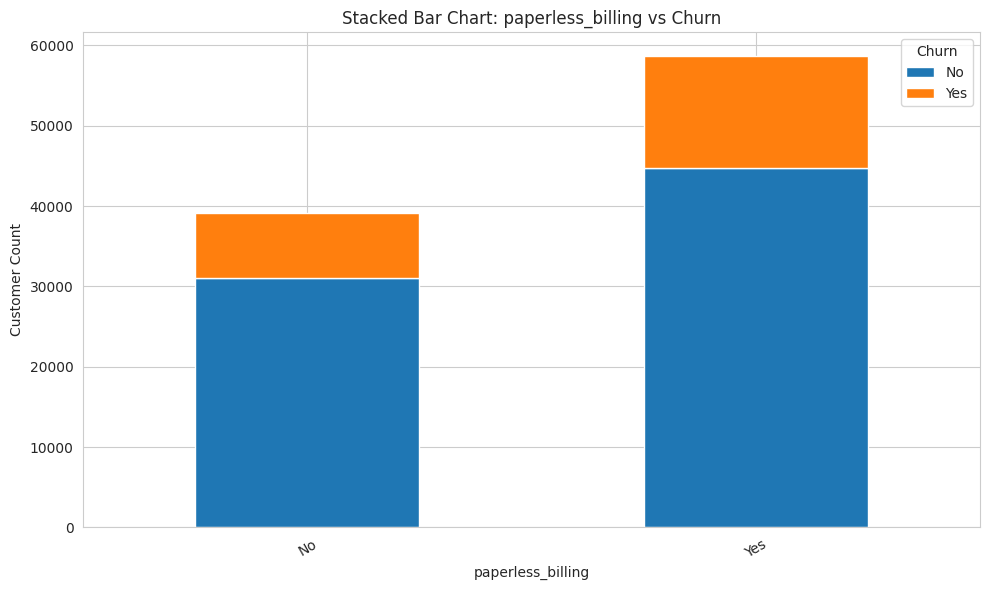

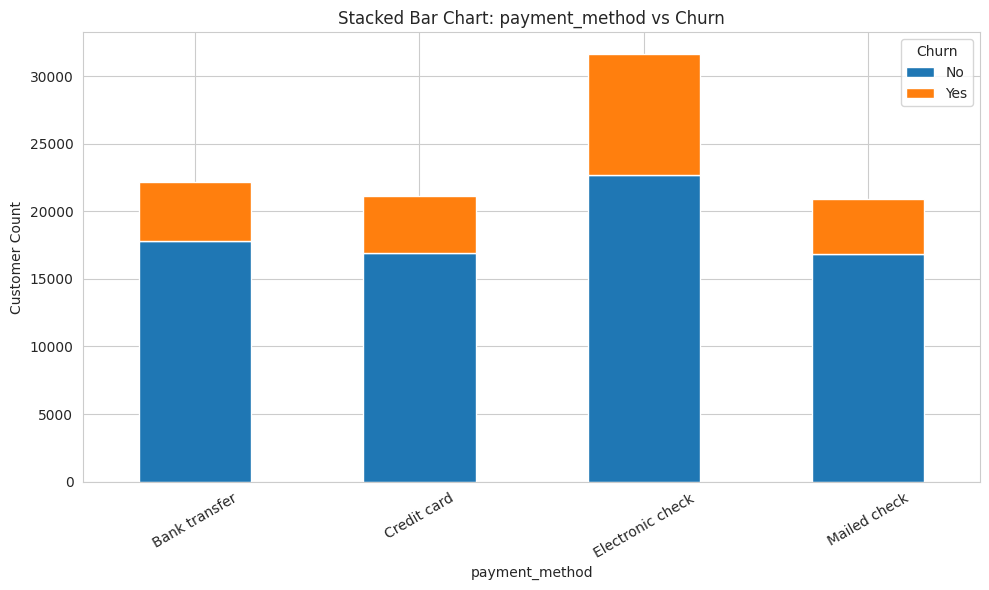

In [19]:

categorical_cols = [
    "gender",
    "contract_type",
    "internet_service",
    "tech_support",
    "online_security",
    "paperless_billing",
    "payment_method"
]

for col in categorical_cols:

    grouped = pd.crosstab(
        df[col],
        df["churn"]
    )

    grouped.plot(
        kind="bar",
        stacked=True,
        figsize=(10, 6)
    )

    plt.title(f"Stacked Bar Chart: {col} vs Churn")
    plt.xlabel(col)
    plt.ylabel("Customer Count")
    plt.xticks(rotation=30)
    plt.legend(title="Churn")
    plt.tight_layout()
    plt.show()


# **multivariate visualization**

**multiple features**

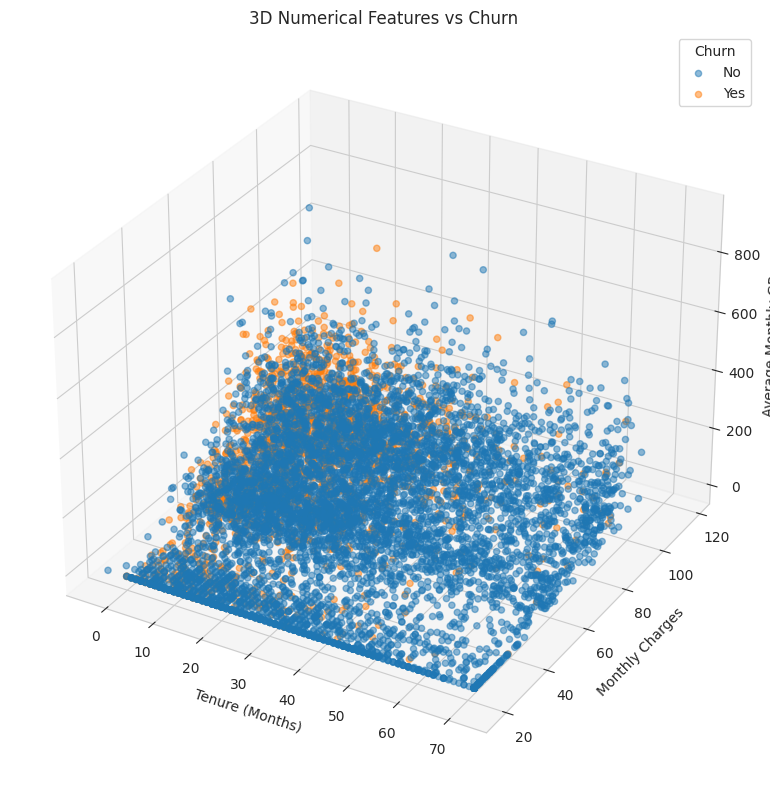

In [20]:
# Sample to make the plot readable
sample_df = df.sample(
    n=min(10000, len(df)),
    random_state=42
)

# 3D Scatter Plot
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

for category in sample_df["churn"].dropna().unique():

    subset = sample_df[sample_df["churn"] == category]

    ax.scatter(
        subset["tenure_months"],
        subset["monthly_charges"],
        subset["avg_monthly_gb"],
        label=str(category),
        alpha=0.5
    )

ax.set_xlabel("Tenure (Months)")
ax.set_ylabel("Monthly Charges")
ax.set_zlabel("Average Monthly GB")

ax.set_title("3D Numerical Features vs Churn")
ax.legend(title="Churn")

plt.tight_layout()
plt.show()

**categorical & categorical & categorical**

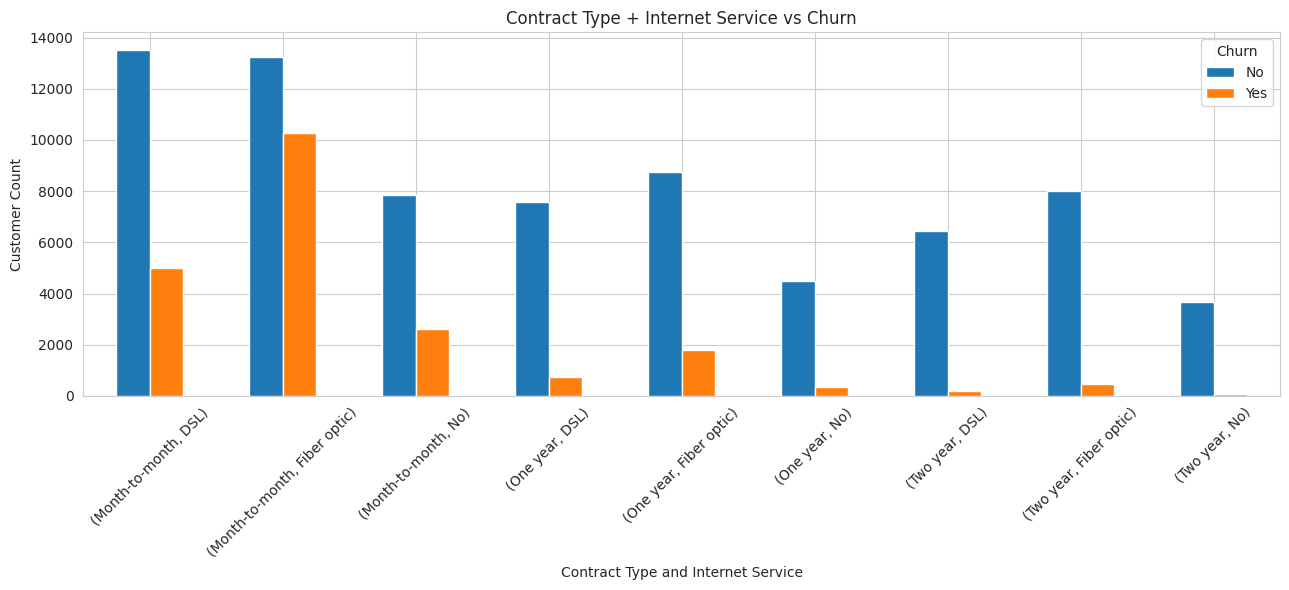

In [21]:

grouped = pd.crosstab(
    [df["contract_type"], df["internet_service"]],
    df["churn"]
)

grouped.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Contract Type + Internet Service vs Churn")
plt.xlabel("Contract Type and Internet Service")
plt.ylabel("Customer Count")
plt.xticks(rotation=45)
plt.legend(title="Churn")
plt.tight_layout()
plt.show()


**categorical & categorical & numerical**

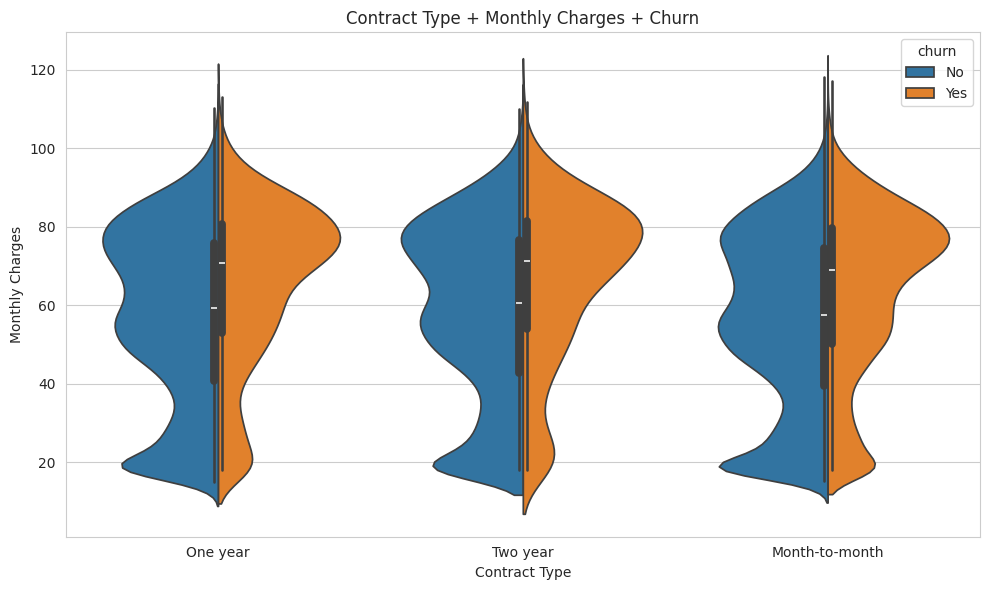

In [22]:

plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x="contract_type",
    y="monthly_charges",
    hue="churn",
    split=True
)

plt.title("Contract Type + Monthly Charges + Churn")
plt.xlabel("Contract Type")
plt.ylabel("Monthly Charges")
plt.tight_layout()
plt.show()


# **outliers visualization**

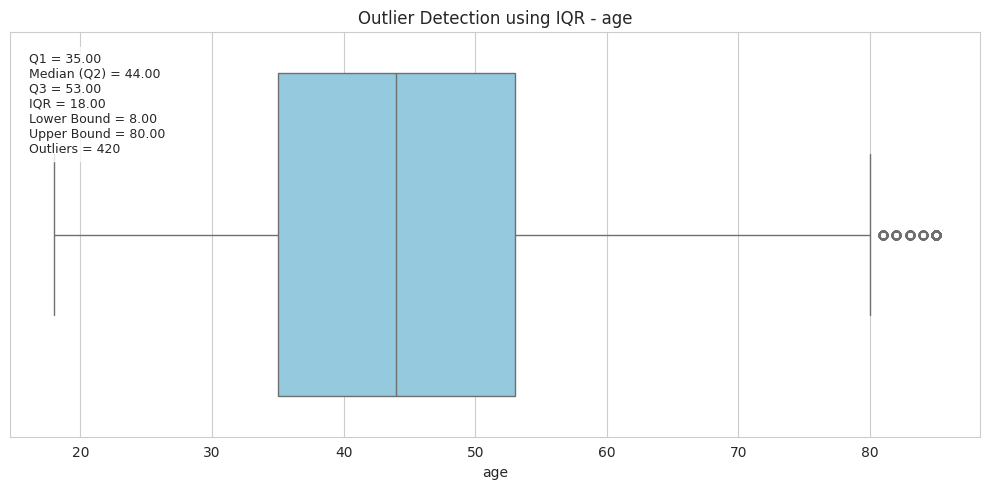

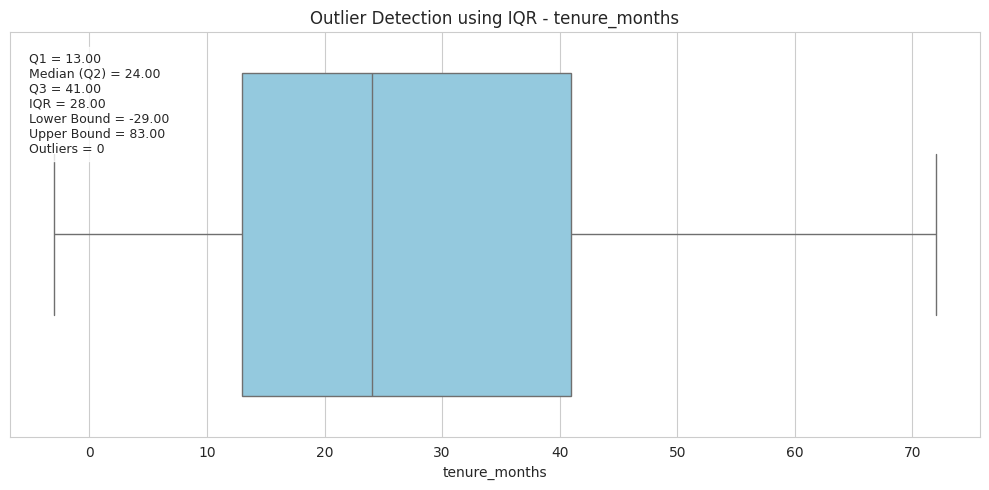

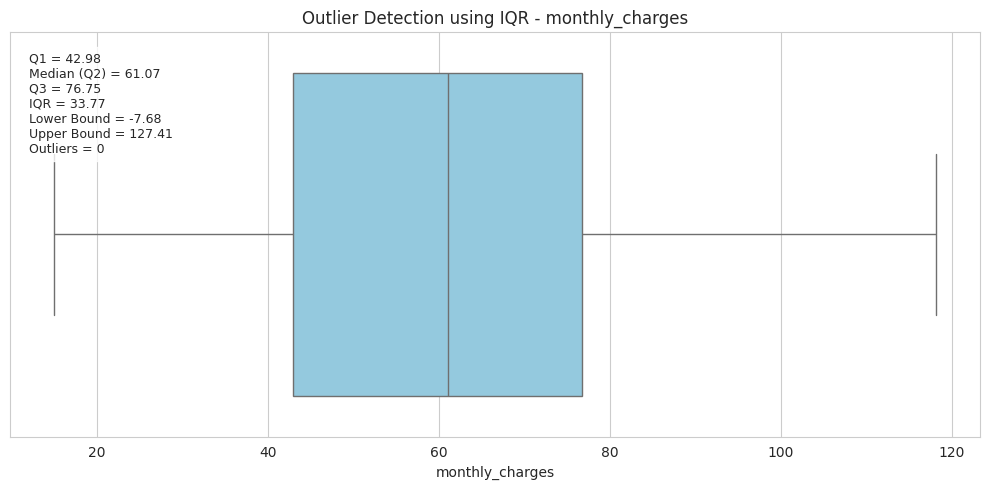

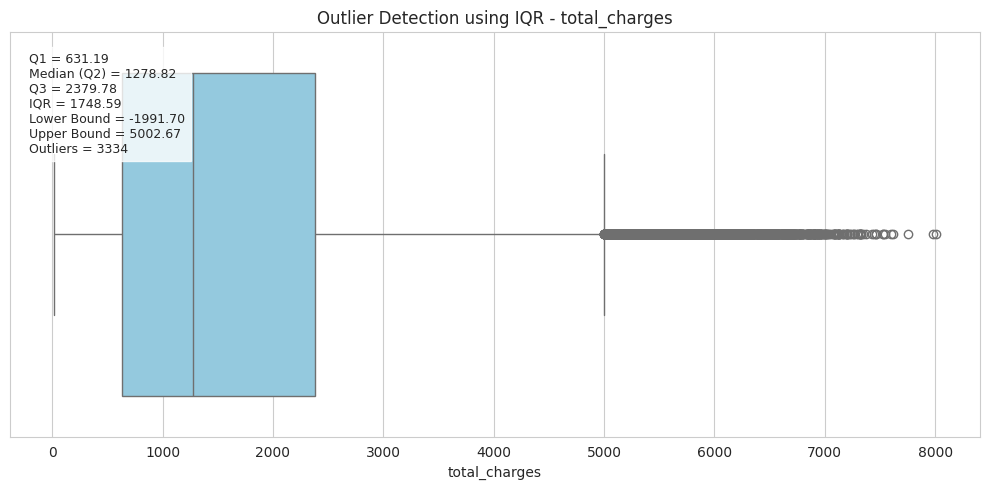

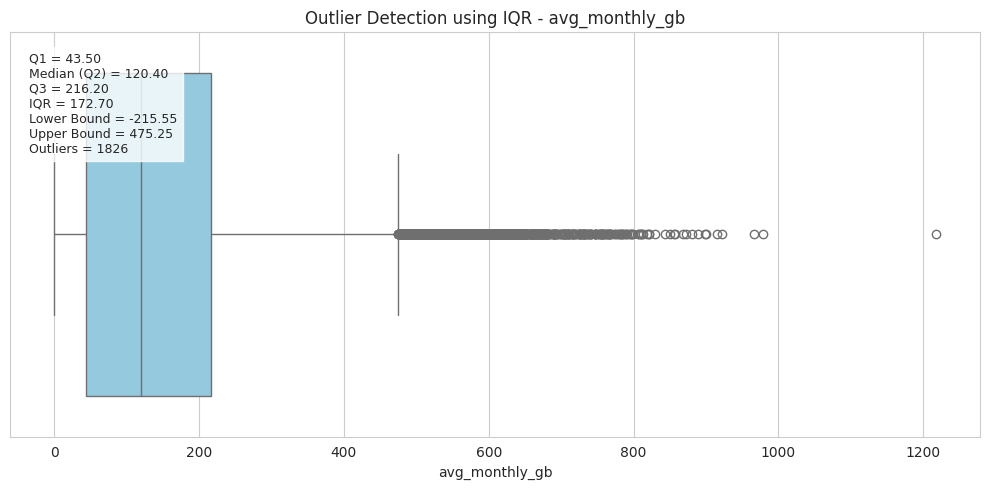

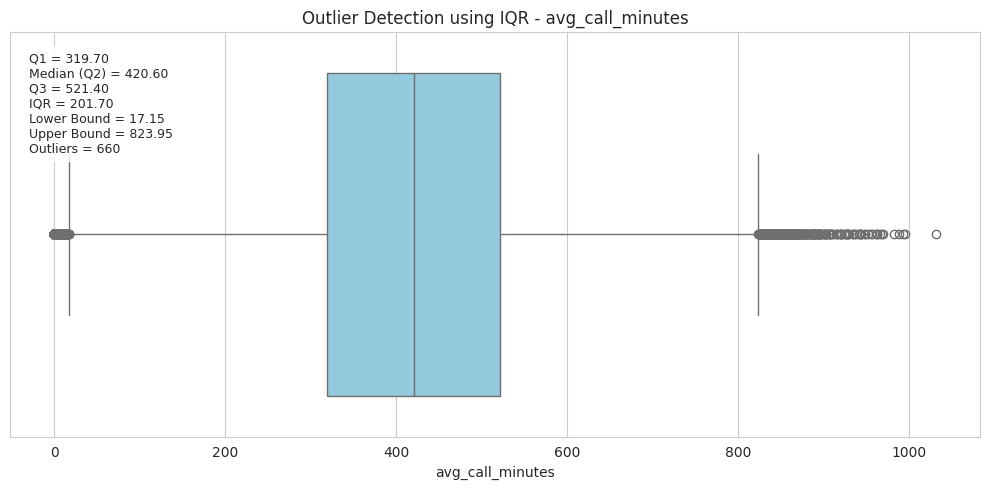

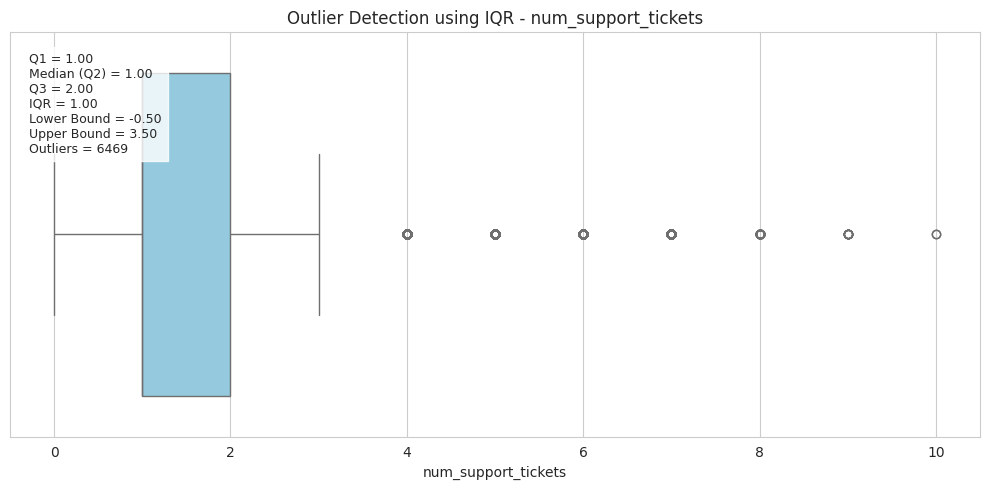

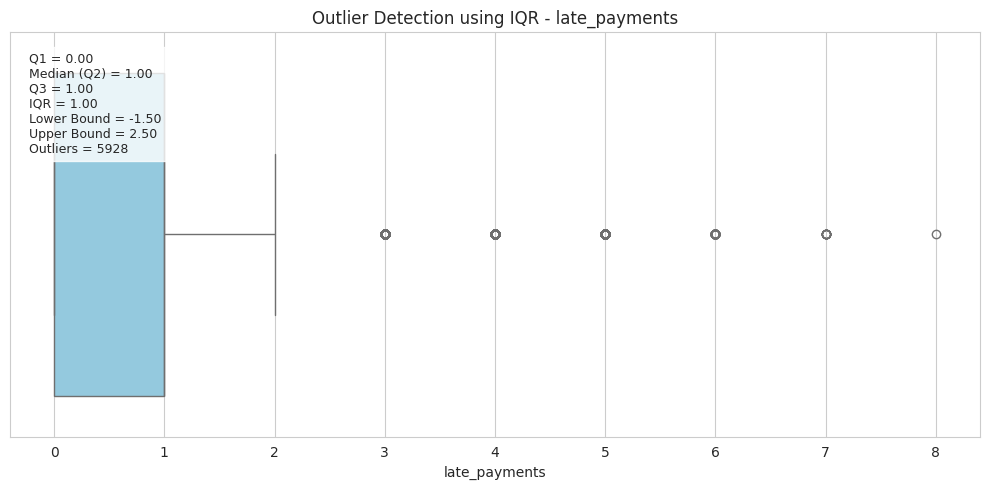

In [23]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = [
    "age",
    "tenure_months",
    "monthly_charges",
    "total_charges",
    "avg_monthly_gb",
    "avg_call_minutes",
    "num_support_tickets",
    "late_payments"
]

for col in numerical_cols:

    data = df[col].dropna()

    # Calculate IQR values
    Q1 = data.quantile(0.25)
    Q2 = data.median()
    Q3 = data.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify outliers
    outliers = data[
        (data < lower_bound) | (data > upper_bound)
    ]

    # Create boxplot
    plt.figure(figsize=(10, 5))

    sns.boxplot(x=data, color="skyblue")

    plt.title(f"Outlier Detection using IQR - {col}")
    plt.xlabel(col)

    # Display IQR information
    iqr_text = (
        f"Q1 = {Q1:.2f}\n"
        f"Median (Q2) = {Q2:.2f}\n"
        f"Q3 = {Q3:.2f}\n"
        f"IQR = {IQR:.2f}\n"
        f"Lower Bound = {lower_bound:.2f}\n"
        f"Upper Bound = {upper_bound:.2f}\n"
        f"Outliers = {len(outliers)}"
    )

    plt.text(
        0.02, 0.95,
        iqr_text,
        transform=plt.gca().transAxes,
        fontsize=9,
        verticalalignment="top",
        bbox=dict(facecolor="white", alpha=0.8)
    )

    plt.tight_layout()
    plt.show()


# **TEST OF ASSOCIATION**

In [24]:

num_cols = [
    "age",
    "tenure_months",
    "monthly_charges",
    "total_charges",
    "avg_monthly_gb",
    "avg_call_minutes",
    "num_support_tickets",
    "late_payments"
]

cat_cols = [
    "gender",
    "contract_type",
    "internet_service",
    "tech_support",
    "online_security",
    "paperless_billing",
    "payment_method"
]

# Work on a copy
d = df.copy()

# Remove missing target values
d = d.dropna(subset=["churn"])

# Convert numerical columns
for col in num_cols:
    d[col] = pd.to_numeric(d[col], errors="coerce")

# Convert categorical columns
for col in cat_cols + ["churn"]:
    d[col] = d[col].astype("category")

print("Prepared dataset shape:", d.shape)
print("\nChurn distribution:")
display(d["churn"].value_counts())


Prepared dataset shape: (97895, 18)

Churn distribution:


,count
churn,
No,75753
Yes,22142


In [25]:
from statsmodels.stats.multitest import multipletests
def add_adjusted_pvalues(result, p_col):

    result = result.copy()
    result["p_adjusted"] = np.nan

    valid = result[p_col].notna()

    if valid.sum() > 0:
        result.loc[valid, "p_adjusted"] = multipletests(
            result.loc[valid, p_col],
            method="fdr_bh"
        )[1]

    result["significant"] = result["p_adjusted"] < 0.05

    return result


# **ANOVA TEST**

**ONE WAY ANOVA**

ONE-WAY ANOVA RESULTS


,feature,F_value,p_value,eta_squared,mean_No,mean_Yes,sample_size,p_adjusted,significant
1,tenure_months,9482.1159,0.000,0.0900,32.0119,18.0298,95934,0.000,True
3,total_charges,4321.0680,0.000,0.0423,1839.5495,1161.9431,97817,0.000,True
2,monthly_charges,1569.1848,0.000,0.0167,56.8542,63.8160,92505,0.000,True
6,num_support_tickets,1355.2088,0.000,0.0144,1.4424,1.8102,92487,0.000,True
7,late_payments,1271.2991,0.000,0.0132,0.7697,1.0359,94949,0.000,True
4,avg_monthly_gb,902.6693,0.000,0.0098,137.4292,167.9412,90812,0.000,True
0,age,136.5831,0.000,0.0015,44.4938,43.2579,93738,0.000,True
5,avg_call_minutes,1.0923,0.296,0.0000,420.9357,419.7140,92994,0.296,False


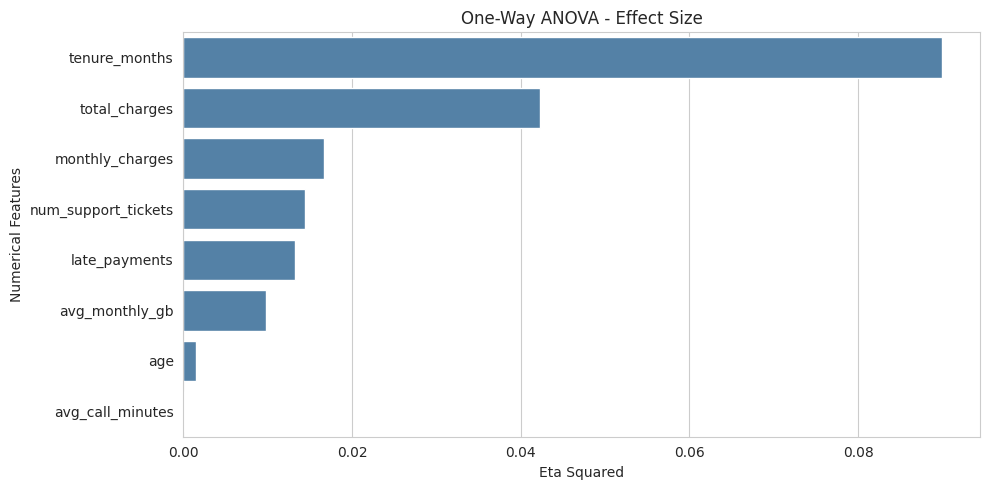

In [26]:

oneway_results = []

for feature in num_cols:

    temp = d[["churn", feature]].dropna()

    groups = [
        group[feature].values
        for _, group in temp.groupby("churn", observed=True)
    ]

    if len(groups) != 2 or any(len(g) < 2 for g in groups):
        continue

    F, p = stats.f_oneway(*groups)

    overall_mean = temp[feature].mean()

    ss_total = (
        (temp[feature] - overall_mean) ** 2
    ).sum()

    ss_between = sum(
        len(g) * (g.mean() - overall_mean) ** 2
        for g in groups
    )

    eta_sq = (
        ss_between / ss_total
        if ss_total > 0 else np.nan
    )

    means = temp.groupby(
        "churn", observed=True
    )[feature].mean()

    oneway_results.append({
        "feature": feature,
        "F_value": F,
        "p_value": p,
        "eta_squared": eta_sq,
        "mean_No": means.get("No", np.nan),
        "mean_Yes": means.get("Yes", np.nan),
        "sample_size": len(temp)
    })

oneway_results = pd.DataFrame(oneway_results)

oneway_results = add_adjusted_pvalues(
    oneway_results, "p_value"
)

oneway_results = oneway_results.sort_values(
    "eta_squared", ascending=False
)

print("ONE-WAY ANOVA RESULTS")
display(oneway_results.round(4))

# Visualization
plt.figure(figsize=(10, 5))

sns.barplot(
    data=oneway_results,
    x="eta_squared",
    y="feature",
    color="steelblue"
)

plt.title("One-Way ANOVA - Effect Size")
plt.xlabel("Eta Squared")
plt.ylabel("Numerical Features")
plt.tight_layout()
plt.show()


**TWO WAY ANOVA**

In [27]:
import statsmodels.api as sm
import statsmodels.formula.api as smf

from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

In [28]:

# Selected combinations for Two-Way ANOVA
two_way_pairs = [
    ("monthly_charges", "contract_type"),
    ("tenure_months", "contract_type"),
    ("total_charges", "internet_service"),
    ("avg_monthly_gb", "internet_service"),
    ("avg_call_minutes", "gender"),
    ("num_support_tickets", "tech_support"),
    ("late_payments", "payment_method"),
    ("age", "gender")
]

twoway_results = []

for num_feature, cat_feature in two_way_pairs:

    temp = d[
        ["churn", cat_feature, num_feature]
    ].dropna().copy()

    temp["churn"] = temp["churn"].cat.remove_unused_categories()
    temp[cat_feature] = temp[cat_feature].cat.remove_unused_categories()

    if temp["churn"].nunique() < 2:
        continue

    if temp[cat_feature].nunique() < 2:
        continue

    formula = (
        f'Q("{num_feature}") ~ '
        f'C(Q("churn"), Sum) * C(Q("{cat_feature}"), Sum)'
    )

    try:
        model = ols(formula, data=temp).fit()

        table = anova_lm(model, typ=3)

        residual_ss = table.loc["Residual", "sum_sq"]

        churn_term = 'C(Q("churn"), Sum)'
        cat_term = f'C(Q("{cat_feature}"), Sum)'
        interaction_term = f'{churn_term}:{cat_term}'

        row = {
            "numerical_feature": num_feature,
            "second_factor": cat_feature,
            "sample_size": len(temp)
        }

        terms = {
            "churn": churn_term,
            "second_factor": cat_term,
            "interaction": interaction_term
        }

        for label, term in terms.items():

            if term in table.index:

                ss = table.loc[term, "sum_sq"]

                row[f"{label}_F"] = table.loc[term, "F"]
                row[f"{label}_p"] = table.loc[term, "PR(>F)"]

                row[f"{label}_partial_eta_sq"] = (
                    ss / (ss + residual_ss)
                    if ss + residual_ss > 0
                    else np.nan
                )

            else:
                row[f"{label}_F"] = np.nan
                row[f"{label}_p"] = np.nan
                row[f"{label}_partial_eta_sq"] = np.nan

        twoway_results.append(row)

    except Exception as e:
        print(f"Skipped {num_feature} and {cat_feature}: {e}")


# Convert results into DataFrame
twoway_results = pd.DataFrame(twoway_results)

# Apply multiple-testing correction separately
for effect in ["churn", "second_factor", "interaction"]:

    twoway_results = add_adjusted_pvalues(
        twoway_results,
        f"{effect}_p"
    )

    twoway_results = twoway_results.rename(columns={
        "p_adjusted": f"{effect}_p_adjusted",
        "significant": f"{effect}_significant"
    })

# Rank by interaction effect size
twoway_results = twoway_results.sort_values(
    "interaction_partial_eta_sq",
    ascending=False
)

print("TWO-WAY ANOVA RESULTS")
display(twoway_results.round(4))


TWO-WAY ANOVA RESULTS


,numerical_feature,second_factor,sample_size,churn_F,churn_p,churn_partial_eta_sq,second_factor_F,second_factor_p,second_factor_partial_eta_sq,interaction_F,interaction_p,interaction_partial_eta_sq,churn_p_adjusted,churn_significant,second_factor_p_adjusted,second_factor_significant,interaction_p_adjusted,interaction_significant
2,total_charges,internet_service,94947,4831.6320,0.0000,0.0484,6699.5932,0.0000,0.1237,537.4005,0.0000,0.0112,0.0000,True,0.0000,True,0.0000,True
1,tenure_months,contract_type,95934,1126.5848,0.0000,0.0116,9601.6084,0.0000,0.1668,94.0451,0.0000,0.0020,0.0000,True,0.0000,True,0.0000,True
6,late_payments,payment_method,92991,549.5479,0.0000,0.0059,3175.9473,0.0000,0.0929,30.1003,0.0000,0.0010,0.0000,True,0.0000,True,0.0000,True
5,num_support_tickets,tech_support,92487,760.5266,0.0000,0.0082,558.5720,0.0000,0.0119,18.5153,0.0000,0.0004,0.0000,True,0.0000,True,0.0000,True
3,avg_monthly_gb,internet_service,88152,0.6823,0.4088,0.0000,33046.5980,0.0000,0.4285,1.3654,0.2553,0.0000,0.4088,False,0.0000,True,0.3294,False
0,monthly_charges,contract_type,92505,608.4291,0.0000,0.0065,34.5150,0.0000,0.0007,1.2605,0.2835,0.0000,0.0000,True,0.0000,True,0.3294,False
4,avg_call_minutes,gender,92082,1.2087,0.2716,0.0000,0.7769,0.4598,0.0000,1.2441,0.2882,0.0000,0.3104,False,0.5255,False,0.3294,False
7,age,gender,92813,16.7137,0.0000,0.0002,0.4300,0.6505,0.0000,0.2037,0.8157,0.0000,0.0001,True,0.6505,False,0.8157,False


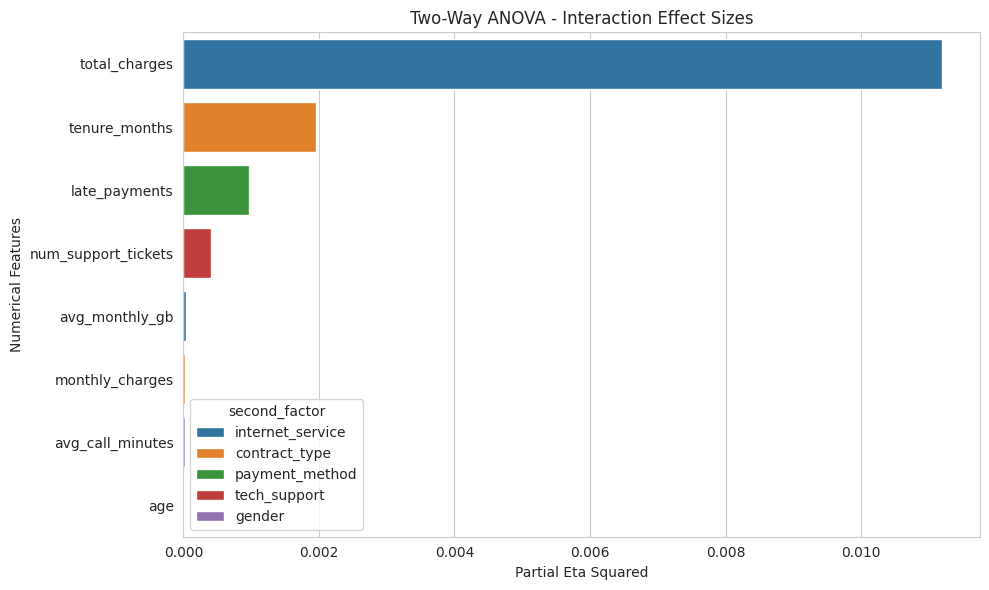

In [29]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=twoway_results,
    x="interaction_partial_eta_sq",
    y="numerical_feature",
    hue="second_factor"
)

plt.title("Two-Way ANOVA - Interaction Effect Sizes")
plt.xlabel("Partial Eta Squared")
plt.ylabel("Numerical Features")
plt.tight_layout()
plt.show()


# **CHI SQUARE TEST**

CHI-SQUARE RESULTS


,feature,chi_square,degrees_of_freedom,p_value,cramers_v,sample_size,min_expected_frequency,p_adjusted,significant
1,contract_type,9520.0966,2,0.0000,0.3118,97895,4394.4728,0.0000,True
2,internet_service,2067.6279,2,0.0000,0.1475,95024,4321.2056,0.0000,True
6,payment_method,841.9113,3,0.0000,0.0937,95884,4735.3771,0.0000,True
4,online_security,712.8605,2,0.0000,0.0853,97895,4450.1134,0.0000,True
3,tech_support,688.7796,2,0.0000,0.0839,97895,4450.1134,0.0000,True
5,paperless_billing,115.9103,1,0.0000,0.0344,97895,8864.4902,0.0000,True
0,gender,3.4702,2,0.1764,0.0060,96940,229.7476,0.1764,False



EXPECTED FREQUENCY DIAGNOSTICS


,feature,expected_below_5,total_expected_cells,percent_expected_below_5
0,gender,0,6,0.0
1,contract_type,0,6,0.0
2,internet_service,0,6,0.0
3,tech_support,0,6,0.0
4,online_security,0,6,0.0
5,paperless_billing,0,4,0.0
6,payment_method,0,8,0.0


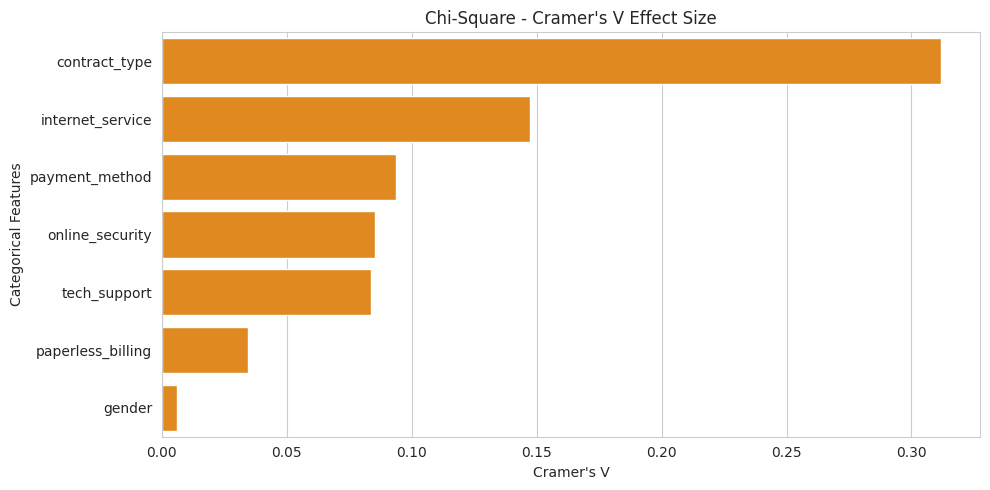

In [30]:

from scipy.stats import chi2_contingency
from statsmodels.stats.multitest import multipletests

chi_results = []
expected_diagnostics = []

for feature in cat_cols:

    temp = d[[feature, "churn"]].dropna()

    contingency_table = pd.crosstab(
        temp[feature],
        temp["churn"]
    )

    if (
        contingency_table.shape[0] < 2
        or contingency_table.shape[1] < 2
    ):
        continue

    chi2, p, dof, expected = chi2_contingency(
        contingency_table,
        correction=False
    )

    n = contingency_table.to_numpy().sum()

    min_dimension = min(
        contingency_table.shape[0] - 1,
        contingency_table.shape[1] - 1
    )

    cramers_v = np.sqrt(
        chi2 / (n * min_dimension)
    )

    chi_results.append({
        "feature": feature,
        "chi_square": chi2,
        "degrees_of_freedom": dof,
        "p_value": p,
        "cramers_v": cramers_v,
        "sample_size": n,
        "min_expected_frequency": expected.min()
    })

    expected_diagnostics.append({
        "feature": feature,
        "expected_below_5": (expected < 5).sum(),
        "total_expected_cells": expected.size,
        "percent_expected_below_5": (
            (expected < 5).sum() / expected.size * 100
        )
    })

# Main Chi-Square results
chi_results = pd.DataFrame(chi_results)

chi_results["p_adjusted"] = multipletests(
    chi_results["p_value"],
    method="fdr_bh"
)[1]

chi_results["significant"] = (
    chi_results["p_adjusted"] < 0.05
)

chi_results = chi_results.sort_values(
    "cramers_v",
    ascending=False
)

print("CHI-SQUARE RESULTS")
display(chi_results.round(4))

# Expected frequency diagnostics
expected_diagnostics_df = pd.DataFrame(
    expected_diagnostics
)

print("\nEXPECTED FREQUENCY DIAGNOSTICS")
display(expected_diagnostics_df.round(4))

# Cramer's V visualization
plt.figure(figsize=(10, 5))

sns.barplot(
    data=chi_results,
    x="cramers_v",
    y="feature",
    color="darkorange"
)

plt.title("Chi-Square - Cramer's V Effect Size")
plt.xlabel("Cramer's V")
plt.ylabel("Categorical Features")

plt.tight_layout()
plt.show()


In [31]:
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
import pandas as pd

# All raw predictor columns. RFE (below) selects 15 of the one-hot encoded
# columns built from these, inside the pipeline.
input_features = [
    "age",
    "tenure_months",
    "monthly_charges",
    "total_charges",
    "avg_monthly_gb",
    "avg_call_minutes",
    "num_support_tickets",
    "late_payments",
    "gender",
    "contract_type",
    "internet_service",
    "tech_support",
    "online_security",
    "paperless_billing",
    "payment_method"
]

# 1. Select predictors and retain churn as the target
X = df[input_features].copy()
y = df["churn"].copy()

# 2. Split BEFORE undersampling: 70% train, 30% original test
X_train_original, X_test, y_train_original, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# 3. Undersample ONLY the training data
train_data = X_train_original.copy()
train_data["churn"] = y_train_original

no_class = train_data[train_data["churn"] == "No"]
yes_class = train_data[train_data["churn"] == "Yes"]

if len(no_class) < len(yes_class):
    raise ValueError("Expected 'No' to be the majority class for undersampling.")

no_under = resample(
    no_class,
    replace=False,
    n_samples=len(yes_class),
    random_state=42
)

train_balanced = pd.concat(
    [no_under, yes_class],
    axis=0
).sample(frac=1, random_state=42)

X_train = train_balanced.drop(columns=["churn"])
y_train = train_balanced["churn"]

# 4. Keep the 30% test set ORIGINAL and imbalanced.
# Do not undersample X_test or y_test.

print("Original dataset shape:", X.shape)
print("Training shape before undersampling:", X_train_original.shape)
print("Training shape after undersampling:", X_train.shape)
print("Testing shape (original 30%):", X_test.shape)

print("\nBalanced training distribution:")
print(y_train.value_counts())
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nOriginal testing distribution (NOT undersampled):")
print(y_test.value_counts())
print((y_test.value_counts(normalize=True) * 100).round(2))

Original dataset shape: (97895, 15)
Training shape before undersampling: (68526, 15)
Training shape after undersampling: (30998, 15)
Testing shape (original 30%): (29369, 15)

Balanced training distribution:
churn
Yes    15499
No     15499
Name: count, dtype: int64
churn
Yes    50.0
No     50.0
Name: proportion, dtype: float64

Original testing distribution (NOT undersampled):
churn
No     22726
Yes     6643
Name: count, dtype: int64
churn
No     77.38
Yes    22.62
Name: proportion, dtype: float64


# **RFE**

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify numerical and categorical predictor columns
num_cols = X_train.select_dtypes(include=["number"]).columns.tolist()
cat_cols = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Ensure missing categorical values are represented as np.nan.
# No statistics are learned here; imputers learn inside each CV training fold.
for col in cat_cols:
    X_train[col] = X_train[col].astype(object).where(X_train[col].notna(), np.nan)
    X_test[col] = X_test[col].astype(object).where(X_test[col].notna(), np.nan)

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)
print("Preprocessing pipeline created. Imputation is fitted inside each training fold.")

Numerical columns: ['age', 'tenure_months', 'monthly_charges', 'total_charges', 'avg_monthly_gb', 'avg_call_minutes', 'num_support_tickets', 'late_payments']
Categorical columns: ['gender', 'contract_type', 'internet_service', 'tech_support', 'online_security', 'paperless_billing', 'payment_method']
Preprocessing pipeline created. Imputation is fitted inside each training fold.


In [33]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Logistic Regression estimator used by RFE
rfe_estimator = LogisticRegression(
    max_iter=3000,
    class_weight="balanced",
    solver="liblinear",
    random_state=42
)

rfe = RFE(
    estimator=rfe_estimator,
    n_features_to_select=15,
    step=2
)

final_lr = LogisticRegression(
    max_iter=3000,
    random_state=42
)

# Exploratory pipeline: it uses the same preprocessing and the same RFE settings
# (step=2) as the CV and tuning pipelines, so the features listed below match the
# features the final model uses. Cross-validation also fits a fresh RFE selector
# inside every fold.
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("feature_selection", rfe),
    ("model", final_lr)
])

print("Training-only RFE pipeline created successfully.")

Training-only RFE pipeline created successfully.


In [34]:
lr_pipeline.fit(X_train, y_train)

# Get feature names after preprocessing
all_feature_names = (
    lr_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get RFE selection results
rfe_final = lr_pipeline.named_steps["feature_selection"]

rfe_results = pd.DataFrame({
    "feature": all_feature_names,
    "ranking": rfe_final.ranking_,
    "selected": rfe_final.support_
})

rfe_results = rfe_results.sort_values(
    by=["selected", "ranking"],
    ascending=[False, True]
).reset_index(drop=True)

display(rfe_results)

print("Selected features:")
print(
    rfe_results.loc[
        rfe_results["selected"], "feature"
    ].tolist()
)

,feature,ranking,selected
0,num__age,1,True
1,num__tenure_months,1,True
2,num__monthly_charges,1,True
3,num__total_charges,1,True
4,num__num_support_tickets,1,True
5,num__late_payments,1,True
6,cat__contract_type_Month-to-month,1,True
7,cat__contract_type_Two year,1,True
8,cat__internet_service_DSL,1,True
9,cat__tech_support_No internet service,1,True


Selected features:
['num__age', 'num__tenure_months', 'num__monthly_charges', 'num__total_charges', 'num__num_support_tickets', 'num__late_payments', 'cat__contract_type_Month-to-month', 'cat__contract_type_Two year', 'cat__internet_service_DSL', 'cat__tech_support_No internet service', 'cat__tech_support_Yes', 'cat__online_security_No internet service', 'cat__online_security_Yes', 'cat__paperless_billing_No', 'cat__payment_method_Electronic check']


In [35]:
selected_features = rfe_results.loc[
    rfe_results["selected"], "feature"
].tolist()

print("Number of selected encoded features:", len(selected_features))

print("\nSelected features:")
for feature in selected_features:
    print(feature)

Number of selected encoded features: 15

Selected features:
num__age
num__tenure_months
num__monthly_charges
num__total_charges
num__num_support_tickets
num__late_payments
cat__contract_type_Month-to-month
cat__contract_type_Two year
cat__internet_service_DSL
cat__tech_support_No internet service
cat__tech_support_Yes
cat__online_security_No internet service
cat__online_security_Yes
cat__paperless_billing_No
cat__payment_method_Electronic check


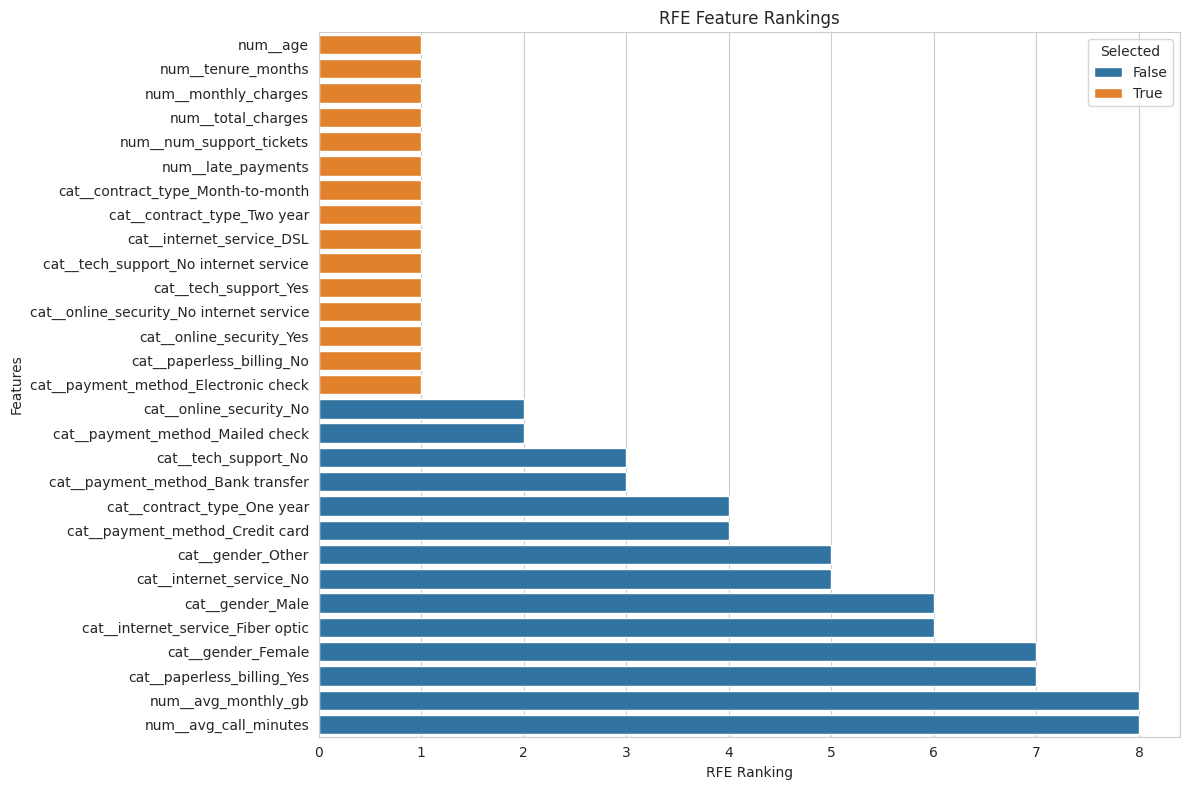

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.barplot(
    data=rfe_results,
    x="ranking",
    y="feature",
    hue="selected",
    dodge=False
)

plt.title("RFE Feature Rankings")
plt.xlabel("RFE Ranking")
plt.ylabel("Features")
plt.legend(title="Selected")
plt.tight_layout()
plt.show()

In [37]:
numerical_features = [  "age",
    "tenure_months",
    "monthly_charges",
    "total_charges",
    "avg_monthly_gb",
    "avg_call_minutes",
    "num_support_tickets",
    "late_payments"]
results = []
for col in numerical_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) |(df[col] > upper_bound)]
    results.append({'Column': col,'Q1': Q1,'Q3': Q3,'IQR': IQR,'Lower Bound': lower_bound,'Upper Bound': upper_bound,'Outliers Count': len(outliers)})
iqr_table = pd.DataFrame(results)
iqr_table

,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outliers Count
0,age,35.00,53.00,18.00,8.000,80.000,420
1,tenure_months,13.00,41.00,28.00,-29.000,83.000,0
2,monthly_charges,42.98,76.75,33.77,-7.675,127.405,0
3,total_charges,631.19,2379.78,1748.59,-1991.695,5002.665,3334
4,avg_monthly_gb,43.50,216.20,172.70,-215.550,475.250,1826
5,avg_call_minutes,319.70,521.40,201.70,17.150,823.950,660
6,num_support_tickets,1.00,2.00,1.00,-0.500,3.500,6469
7,late_payments,0.00,1.00,1.00,-1.500,2.500,5928


In [38]:
# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check target distribution
print("\nChurn distribution:")
print(df["churn"].value_counts(dropna=False))

# Check target data type
print("\nTarget dtype:")
print(df["churn"].dtype)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (97895, 18)

Churn distribution:
churn
No     75753
Yes    22142
Name: count, dtype: int64

Target dtype:
object

Missing values:
customer_id               0
gender                  955
age                    4157
signup_date               0
contract_type             0
tenure_months          1961
internet_service       2871
tech_support              0
online_security           0
paperless_billing         0
payment_method         2011
monthly_charges        5390
total_charges            78
avg_monthly_gb         7083
avg_call_minutes       4901
num_support_tickets    5408
late_payments          2946
churn                     0
dtype: int64

Duplicate rows: 0


In [39]:
!pip install -q lightgbm catboost

In [40]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

# **MODEL COMPARISON (10-fold CV on the balanced training data)**

Note: the CV folds are balanced (the training data was undersampled), so CV accuracy is not comparable to accuracy on the original, imbalanced test set. Compare the final test accuracy with the majority-class baseline printed in the final evaluation.

In [41]:
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    make_scorer,
    precision_score,
    recall_score,
    f1_score
)

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score,
        pos_label="Yes",
        zero_division=0
    ),
    "recall": make_scorer(
        recall_score,
        pos_label="Yes",
        zero_division=0
    ),
    "f1": make_scorer(
        f1_score,
        pos_label="Yes",
        zero_division=0
    ),
    "roc_auc": "roc_auc"
}

def make_model_pipeline(model):
    # A fresh preprocessor and RFE selector are fitted within each CV fold.
    return Pipeline([
        ("preprocessor", preprocessor),
        ("feature_selection", RFE(
            estimator=LogisticRegression(
                max_iter=3000,
                class_weight="balanced",
                solver="liblinear",
                random_state=42
            ),
            n_features_to_select=15,
            step=2
        )),
        ("model", model)
    ])

def evaluate_model(model, model_name):
    pipeline = make_model_pipeline(model)

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1,
        error_score="raise"
    )

    results = pd.DataFrame([{
        "Model": model_name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    }])

    display(results.round(4))
    return results

In [42]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=2000
)

lr_results = evaluate_model(
    lr_model,
    "Logistic Regression"
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.7162,0.6942,0.7731,0.7315,0.7858


In [43]:
lr_balanced_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced"
)

lr_balanced_results = evaluate_model(
    lr_balanced_model,
    "Logistic Regression Balanced"
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression Balanced,0.7162,0.6942,0.7731,0.7315,0.7858


In [44]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_results = evaluate_model(
    dt_model,
    "Decision Tree"
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Decision Tree,0.6194,0.6185,0.6233,0.6208,0.6194


In [45]:
dt_balanced_model = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

dt_balanced_results = evaluate_model(
    dt_balanced_model,
    "Decision Tree Balanced"
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Decision Tree Balanced,0.6199,0.6192,0.623,0.621,0.6199


In [46]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    random_state=42,
    n_jobs=1
)

rf_results = evaluate_model(
    rf_model,
    "Random Forest"
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.6939,0.6837,0.7219,0.7022,0.7576


In [47]:
rf_balanced_model = RandomForestClassifier(
    random_state=42,
    class_weight="balanced",
    n_jobs=1
)

rf_balanced_results = evaluate_model(
    rf_balanced_model,
    "Random Forest Balanced"
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest Balanced,0.6945,0.6842,0.7226,0.7028,0.7585


In [48]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    random_state=42
)

gb_results = evaluate_model(
    gb_model,
    "Gradient Boosting"
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Gradient Boosting,0.7135,0.6908,0.7735,0.7297,0.7826


In [49]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(
    n_neighbors=5,
    n_jobs=1
)

knn_results = evaluate_model(
    knn_model,
    "KNN"
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,KNN,0.6736,0.6653,0.699,0.6817,0.7235


In [50]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

nb_results = evaluate_model(
    nb_model,
    "Gaussian Naive Bayes"
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Gaussian Naive Bayes,0.6934,0.6522,0.8302,0.7303,0.7685


In [51]:
from sklearn.ensemble import AdaBoostClassifier

ada_model = AdaBoostClassifier(
    random_state=42
)

ada_results = evaluate_model(
    ada_model,
    "AdaBoost"
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,AdaBoost,0.7112,0.6885,0.772,0.7278,0.7795


In [52]:
from sklearn.ensemble import ExtraTreesClassifier

et_model = ExtraTreesClassifier(
    random_state=42,
    n_jobs=1
)

et_results = evaluate_model(
    et_model,
    "Extra Trees"
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Extra Trees,0.6815,0.6733,0.7053,0.6888,0.7447


In [53]:
from lightgbm import LGBMClassifier

lgbm_model = LGBMClassifier(
    random_state=42,
    verbosity=-1,
    n_jobs=1
)

lgbm_results = evaluate_model(
    lgbm_model,
    "LightGBM"
)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,LightGBM,0.7111,0.6896,0.7681,0.7267,0.7804


In [54]:
from catboost import CatBoostClassifier

catboost_model = CatBoostClassifier(
    verbose=0,
    random_seed=42,
    thread_count=1
)

catboost_results = evaluate_model(
    catboost_model,
    "CatBoost"
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,CatBoost,0.7102,0.6895,0.7651,0.7253,0.7792


In [55]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

lda_model = LinearDiscriminantAnalysis()

lda_results = evaluate_model(
    lda_model,
    "Linear Discriminant Analysis"
)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Linear Discriminant Analysis,0.7154,0.6877,0.7895,0.735,0.7851


In [56]:
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

qda_model = QuadraticDiscriminantAnalysis()

qda_results = evaluate_model(
    qda_model,
    "Quadratic Discriminant Analysis"
)

/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
  warnings.warn(
/usr/local/lib/p

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Quadratic Discriminant Analysis,0.5622,0.5938,0.4678,0.4641,0.592


In [57]:
from xgboost import XGBClassifier
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

# XGBoost requires numeric target labels; this is a temporary copy.
# The original y_train remains "Yes"/"No".
y_train_num = (y_train == "Yes").astype(int)

xgb_scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, pos_label=1, zero_division=0),
    "recall": make_scorer(recall_score, pos_label=1, zero_division=0),
    "f1": make_scorer(f1_score, pos_label=1, zero_division=0),
    "roc_auc": "roc_auc"
}

def evaluate_xgb(model, model_name):
    pipeline = make_model_pipeline(model)

    scores = cross_validate(
        pipeline,
        X_train,
        y_train_num,
        cv=cv,
        scoring=xgb_scoring,
        n_jobs=1,
        error_score="raise"
    )

    results = pd.DataFrame([{
        "Model": model_name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1 Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    }])

    display(results.round(4))
    return results

xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=1
)

xgb_results = evaluate_xgb(xgb_model, "XGBoost")

# Do not create a redundant scale_pos_weight experiment:
# undersampled training data already has a 1:1 class ratio.

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost,0.7137,0.692,0.7706,0.7291,0.7829


In [58]:
all_cv_results = pd.concat([
    lr_results,
    lr_balanced_results,
    dt_results,
    dt_balanced_results,
    rf_results,
    rf_balanced_results,
    gb_results,
    knn_results,
    nb_results,
    ada_results,
    et_results,
    lgbm_results,
    catboost_results,
    lda_results,
    qda_results,
    xgb_results
], ignore_index=True)

all_cv_results = all_cv_results.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

display(all_cv_results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression Balanced,0.7162,0.6942,0.7731,0.7315,0.7858
1,Logistic Regression,0.7162,0.6942,0.7731,0.7315,0.7858
2,Linear Discriminant Analysis,0.7154,0.6877,0.7895,0.7350,0.7851
3,XGBoost,0.7137,0.6920,0.7706,0.7291,0.7829
4,Gradient Boosting,0.7135,0.6908,0.7735,0.7297,0.7826
5,LightGBM,0.7111,0.6896,0.7681,0.7267,0.7804
6,AdaBoost,0.7112,0.6885,0.7720,0.7278,0.7795
7,CatBoost,0.7102,0.6895,0.7651,0.7253,0.7792
8,Gaussian Naive Bayes,0.6934,0.6522,0.8302,0.7303,0.7685
9,Random Forest Balanced,0.6945,0.6842,0.7226,0.7028,0.7585


In [59]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from scipy.stats import loguniform

# Pipeline: preprocessing -> RFE (fitted inside every CV fold) -> Logistic Regression
lr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("feature_selection", RFE(
        estimator=LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            solver="liblinear",
            random_state=42
        ),
        n_features_to_select=15,
        step=2
    )),
    ("model", LogisticRegression(max_iter=3000))
])

# Parameter search space
# (class_weight is not searched: the training data is already balanced 1:1)
param_dist = {
    "model__C": loguniform(0.001, 100),
    "model__solver": ["lbfgs", "liblinear"]
}

# The CV folds are balanced, so "accuracy" here is balanced accuracy.
random_search = RandomizedSearchCV(
    estimator=lr_pipeline,
    param_distributions=param_dist,
    n_iter=20,
    scoring="accuracy",
    cv=cv,
    random_state=42,
    n_jobs=2,
    verbose=1,
    error_score="raise"
)

# Fit on training data
random_search.fit(X_train, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV accuracy (balanced folds):")
print(random_search.best_score_)


Fitting 10 folds for each of 20 candidates, totalling 200 fits
Best Parameters:
{'model__C': np.float64(0.14445251022763064), 'model__solver': 'lbfgs'}

Best CV accuracy (balanced folds):
0.7164336258314337


# **THRESHOLD TUNING (on the original class distribution)**

The training data is 50/50, but real data is not. The out-of-fold predictions are re-weighted to the original churn rate and the threshold is chosen for accuracy. The test set is not used here.

In [60]:
import numpy as np
import pandas as pd

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    accuracy_score
)

# Best tuned model
best_model = random_search.best_estimator_
yes_index = list(best_model.classes_).index("Yes")

# Out-of-fold probabilities of churn = Yes on the (balanced) training data
y_train_prob = cross_val_predict(
    best_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=2
)[:, yes_index]

# The balanced training data is 50/50, but the real data is not.
# Weight every row so the metrics reflect the ORIGINAL training churn rate.
churn_rate = (y_train_original == "Yes").mean()
sample_weight = np.where(
    y_train == "Yes",
    churn_rate / 0.5,
    (1 - churn_rate) / 0.5
)

print("Original training churn rate:", round(churn_rate, 4))
print("Reference threshold (1 - churn rate):", round(1 - churn_rate, 2))

# Test different thresholds
thresholds = np.round(np.arange(0.05, 0.96, 0.01), 2)

threshold_results = []

for threshold in thresholds:

    y_pred_threshold = np.where(
        y_train_prob >= threshold,
        "Yes",
        "No"
    )

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_train, y_pred_threshold,
            sample_weight=sample_weight
        ),
        "Precision": precision_score(
            y_train, y_pred_threshold,
            pos_label="Yes",
            zero_division=0,
            sample_weight=sample_weight
        ),
        "Recall": recall_score(
            y_train, y_pred_threshold,
            pos_label="Yes",
            zero_division=0,
            sample_weight=sample_weight
        ),
        "F1 Score": f1_score(
            y_train, y_pred_threshold,
            pos_label="Yes",
            zero_division=0,
            sample_weight=sample_weight
        )
    })

threshold_df = pd.DataFrame(threshold_results)

# Show every 5th threshold to keep the output short
display(threshold_df.iloc[::5].round(4))


Original training churn rate: 0.2262
Reference threshold (1 - churn rate): 0.77


,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.05,0.2712,0.2366,0.9981,0.3825
5,0.10,0.3525,0.2575,0.9891,0.4086
10,0.15,0.4154,0.2762,0.9776,0.4307
15,0.20,0.4649,0.2925,0.9630,0.4487
20,0.25,0.5056,0.3074,0.9460,0.4640
25,0.30,0.5429,0.3224,0.9266,0.4783
30,0.35,0.5773,0.3374,0.9011,0.4909
35,0.40,0.6115,0.3542,0.8717,0.5037
40,0.45,0.6493,0.3753,0.8292,0.5168
45,0.50,0.6853,0.3990,0.7733,0.5264


In [61]:
# Select the threshold with the highest accuracy on the original class distribution.
# (To favour catching churners instead, use "F1 Score" in place of "Accuracy" below.)
best_row = threshold_df.loc[
    threshold_df["Accuracy"].idxmax()
]

best_threshold = best_row["Threshold"]

print("Selected Threshold:", best_threshold)

print("\nPerformance at Selected Threshold (re-weighted to the original class distribution):")
print("Accuracy:", best_row["Accuracy"])
print("Precision:", best_row["Precision"])
print("Recall:", best_row["Recall"])
print("F1 Score:", best_row["F1 Score"])
print("Majority-class baseline accuracy:", max(churn_rate, 1 - churn_rate))


Selected Threshold: 0.8

Performance at Selected Threshold (re-weighted to the original class distribution):
Accuracy: 0.7886406180531361
Precision: 0.6100186506544395
Recall: 0.18162462094328843
F1 Score: 0.2799099295566269
Majority-class baseline accuracy: 0.7738230744534921


FINAL MODEL EVALUATION - ORIGINAL, IMBALANCED 30% TEST SET
Selected Threshold: 0.8

Accuracy: 0.7888930504954204
Majority-class baseline accuracy: 0.7738091184582383
Precision: 0.6103637269556552
Recall: 0.18440463645943098
F1 Score: 0.2832369942196532
ROC-AUC: 0.7779022089184006
PR-AUC: 0.48495414212531873

CLASSIFICATION REPORT
              precision    recall  f1-score   support

          No       0.80      0.97      0.88     22726
         Yes       0.61      0.18      0.28      6643

    accuracy                           0.79     29369
   macro avg       0.71      0.57      0.58     29369
weighted avg       0.76      0.79      0.74     29369



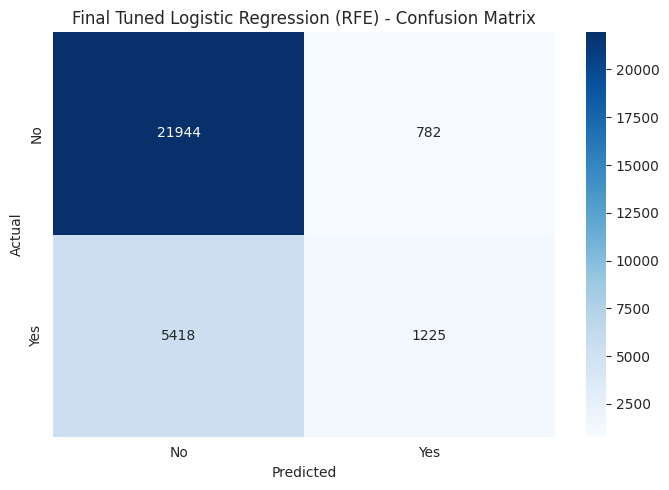

In [62]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

# Fit the best tuned model on complete training data
best_model.fit(X_train, y_train)

# Get probability of churn = Yes
yes_index = list(best_model.classes_).index("Yes")

y_test_prob = best_model.predict_proba(X_test)[:, yes_index]

# Apply optimized threshold
y_test_pred = np.where(
    y_test_prob >= best_threshold,
    "Yes",
    "No"
)

# Final evaluation on the untouched original 30% test set
print("=" * 45)
print("FINAL MODEL EVALUATION - ORIGINAL, IMBALANCED 30% TEST SET")
print("=" * 45)

print("Selected Threshold:", best_threshold)

print("\nAccuracy:",
      accuracy_score(y_test, y_test_pred))

print("Majority-class baseline accuracy:",
      y_test.value_counts(normalize=True).max())

print("Precision:",
      precision_score(
          y_test, y_test_pred,
          pos_label="Yes",
          zero_division=0
      ))

print("Recall:",
      recall_score(
          y_test, y_test_pred,
          pos_label="Yes",
          zero_division=0
      ))

print("F1 Score:",
      f1_score(
          y_test, y_test_pred,
          pos_label="Yes",
          zero_division=0
      ))

print("ROC-AUC:",
      roc_auc_score(
          (y_test == "Yes").astype(int),
          y_test_prob
      ))

print("PR-AUC:",
      average_precision_score(
          (y_test == "Yes").astype(int),
          y_test_prob
      ))

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_test_pred,
    labels=["No", "Yes"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=["No", "Yes"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Final Tuned Logistic Regression (RFE) - Confusion Matrix")

plt.tight_layout()
plt.show()


# **FEATURES USED BY THE FINAL MODEL**

In [63]:
# Names of the encoded columns the final model was actually trained on
final_names = best_model.named_steps["preprocessor"].get_feature_names_out()
final_support = best_model.named_steps["feature_selection"].support_
final_selected = list(final_names[final_support])

print("Encoded features used by the final model:", len(final_selected))
for name in final_selected:
    print(" -", name)

# Consistency check with the exploratory RFE table above
exploratory_selected = rfe_results.loc[rfe_results["selected"], "feature"].tolist()
print("\nSame features as the exploratory RFE table:",
      set(final_selected) == set(exploratory_selected))


Encoded features used by the final model: 15
 - num__age
 - num__tenure_months
 - num__monthly_charges
 - num__total_charges
 - num__num_support_tickets
 - num__late_payments
 - cat__contract_type_Month-to-month
 - cat__contract_type_Two year
 - cat__internet_service_DSL
 - cat__tech_support_No internet service
 - cat__tech_support_Yes
 - cat__online_security_No internet service
 - cat__online_security_Yes
 - cat__paperless_billing_No
 - cat__payment_method_Electronic check

Same features as the exploratory RFE table: True


# **SAVE THE MODEL**

In [64]:
import pickle, sklearn

# Save the fitted model (preprocessing + RFE + model are all inside the pipeline)
with open("churn_model.pkl", "wb") as f:
    pickle.dump(best_model, f)

# Save the threshold and the raw input columns the pipeline expects
meta = {
    "threshold": round(float(best_threshold), 2),
    "features": input_features,
    "test_set": "original_30_percent_not_undersampled",
    "training": "70_percent_random_undersampling",
    "threshold_selection": "max accuracy on original class distribution (out-of-fold, training data only)"
}
with open("churn_meta.pkl", "wb") as f:
    pickle.dump(meta, f)

print("scikit-learn version:", sklearn.__version__)

# Download both files from Colab
try:
    from google.colab import files
    files.download("churn_model.pkl")
    files.download("churn_meta.pkl")
except ImportError:
    print("Not running in Colab - files are saved in the current folder.")

scikit-learn version: 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>